![Banner](../images/09_09_banner_rs_image_classification.png)


# Semantic Segmentation of Crop Types from Sentinel-2: FCN, U-Net, DeepLabV3(+) and SegFormer on the GPU

A chip classifier gives **one label per window**, so field edges, roads and rivers are lost (the previous notebook reached 0.99 accuracy per chip but only about 0.88 per pixel against the CDL). **Semantic segmentation** assigns a class to **every pixel**: the network maps an image $\mathbf X\in\mathbb R^{C\times H\times W}$ to class scores $\mathbf Z\in\mathbb R^{K\times H\times W}$ and the map is $\hat y(i,j)=\arg\max_k Z_k(i,j)$.


## Overview

A chip classifier gives **one label per window**, so field edges, roads and rivers are lost (the previous notebook reached 0.99 accuracy per chip but only about 0.88 per pixel against the CDL). **Semantic segmentation** assigns a class to **every pixel**: the network maps an image $\mathbf X\in\mathbb R^{C\times H\times W}$ to class scores $\mathbf Z\in\mathbb R^{K\times H\times W}$ and the map is $\hat y(i,j)=\arg\max_k Z_k(i,j)$.

This notebook trains segmentation networks on a late-August 2025 **Sentinel-2** scene of the US Corn Belt (10 spectral bands, 10 m) with the 10 m USDA Cropland Data Layer (CDL) as the label mask, inside the AOI `Corn_belt/aoi.geojson`, and asks:

> Which segmentation architecture and loss give the best pixel-level crop map, how do we predict a large raster without tile seams, and how well does an AOI-trained model map the scene fringe outside its training AOI?

* **Data pipeline.** Colour masks $\to$ index masks (`rgb_mask_to_index`), patch sampling, spatial split.
* **Models.** `build_segmenter`: FCN, U-Net, DeepLabV3 / DeepLabV3+, SegFormer, explained with their mathematics.
* **Losses.** Cross-entropy, weighted CE, focal, Dice, Lovász and CE + Dice (`get_loss`), and why CE alone under-weights thin classes.
* **Large rasters.** `sliding_window_predict` with overlap and seam blending.
* **Metrics and output.** `segmentation_metrics` (IoU, mIoU, per-class F1, boundary effects) and `write_class_map` (CRS, transform, class names, colour table).
* **Outside-AOI mapping.** Refit the validation-selected model using only fully AOI-contained patches; map, visualize and export the outside-AOI portion of the scene.

GPU recommended; the experiments shrink automatically on a CPU.


## Core concepts

### Learning objectives

1. Convert colour-coded masks to index masks, sample patches from a large raster and split them spatially without leakage.
2. Explain the building blocks and mathematics of FCN, U-Net, DeepLabV3(+) (atrous convolution, ASPP) and SegFormer (hierarchical transformer encoder, all-MLP decoder).
3. Choose a segmentation loss (CE, weighted CE, focal, Dice, Lovász, CE + Dice) and explain why plain CE under-weights thin classes.
4. Predict a raster larger than GPU memory with overlapping windows and Hann blending, and verify that the seams disappear.
5. Report IoU, mIoU and per-class F1, and quantify the error concentrated at class boundaries.
6. Export the class map as a georeferenced GeoTIFF with class names and a colour table.
7. Train only on AOI-contained patches, then predict and estimate mapped class areas outside the AOI with an explicit coverage mask.

### Contents

1. Setup: libraries, device and data paths
2. From colour masks to index masks: Sentinel-2 stack and CDL labels
3. Patch sampling, spatial split and normalisation
4. Segmentation architectures and the mathematics behind them
5. Segmentation losses: Dice, Lovász and focal versus cross-entropy
6. Training with `train_model`: architecture benchmark
7. Loss ablation: thin classes and mIoU
8. Final model: checkpoint and reload
9. Large-raster inference: sliding windows, overlap and seam blending
10. Metrics: IoU, mIoU, per-class F1 and boundary effects
11. Georeferenced output with `write_class_map`
12. Summary of the experiments
13. AOI-only training and prediction outside the AOI
14. Interpretation, caveats and recommended recipe


### Task and evaluation design

**Data:** Sentinel-2 L2A scene `2025_08_20250826` (10 bands, 10 m) · CDL 2025 at 10 m (labels) · AOI `Corn_belt/aoi.geojson`.

**Task.** *Dense (pixel-wise) classification* into six classes: Corn, Soybeans, Grass/pasture, Developed, Wetland/forest and Other. Thin or small classes (roads and farmsteads in "Developed", rivers in "Wetland/forest") are the hard part and are what the loss comparison is about.

**Honest evaluation.** The $2816\times2816$ px working area is divided into $11\times11$ blocks of 256 px. **Whole blocks** are assigned to train / validation / test (`group_split`), patches are cut only inside their own block, and `check_split_isolation` verifies that no block is shared. Test patches do not overlap each other. The test blocks come from the same scene, so the numbers describe *spatial* generalisation inside the AOI, not transfer to a new date or region. The *AOI-only training and prediction outside the AOI* section then uses only fully AOI-contained patches for a separate AOI-only fit and maps the scene pixels outside the AOI. The CDL is itself a model product, so "accuracy" means agreement with the CDL.

| Step | Functions |
|---|---|
| Masks and patches | `rgb_mask_to_index`, patch sampling, `ChipDataset`, `as_loader` |
| Models | `build_segmenter`, `count_parameters` |
| Losses | `get_loss` (`ce`, `weighted_ce`, `focal`, `dice`, `lovasz`, `ce+dice`), `class_weights` |
| Training | `train_model(task="segmentation")`, `load_checkpoint` |
| Large rasters | `sliding_window_predict` |
| Metrics and output | `segmentation_metrics`, `write_class_map` |


## Setup: libraries, device and data paths

The cell below resolves the data folder from either working directory, checks the files and selects the GPU. On a CPU the epochs and seeds are reduced.

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings, tempfile  # JSON, timing, warnings and temporary folders
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colour maps
import torch  # PyTorch for the segmentation networks
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # data folder seen from the notebook folder or from the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # first candidate that exists
if DATA is None:  # neither was found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
S2 = DATA / "Sentinel_2" / "2025_08_20250826"  # the 26 August 2025 Sentinel-2 scene
CDL_PATH = DATA / "CDL" / "10_m" / "CDL_2025_10m.tif"  # the 2025 CDL resampled to 10 m
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon
for p in (S2, CDL_PATH, AOI_PATH):  # every input ...
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("torch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (epochs and seeds reduced)")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
# epochs, seeds and final epochs (fewer on a CPU)
EPOCHS, SEEDS, FINAL_EPOCHS = (20, [0, 1, 2], 40) if DEVICE == "cuda" else (3, [0], 4)


torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## From colour masks to index masks: Sentinel-2 stack and CDL labels

### Sentinel-2 reflectance on a common 10 m grid
Four bands are native 10 m; six 20 m bands are bilinearly resampled to the 10 m grid. DNs are scaled to reflectance with the L2A factor $\rho=10^{-4}\,\mathrm{DN}$ (the DNs of these files are already offset-corrected). Pixels flagged by the scene classification layer (no data, saturated, cloud shadow, cloud, cirrus) become `NaN` and are later ignored in the loss and the metrics.


In [2]:
# the ten Sentinel-2 bands
BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
ref = rioxarray.open_rasterio(S2 / "red.tif").squeeze(drop=True)  # the 10 m red band is the reference grid
layers = []  # one array per band
for b in BANDS:  # each band
    a = rioxarray.open_rasterio(S2 / f"{b}.tif").squeeze(drop=True)  # read it
    if a.shape != ref.shape:  # a 20 m band ...
        a = a.rio.reproject_match(ref, resampling=1)  # ... is resampled bilinearly to 10 m
    layers.append(a.astype("float32"))  # keep it as float32
dn = xr.concat(layers, dim="band").assign_coords(band=BANDS)  # stack along "band"
# scene classification layer on the 10 m grid
scl = rioxarray.open_rasterio(S2 / "scl.tif").squeeze(drop=True).rio.reproject_match(ref, resampling=0).values
bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11])  # no data, saturated, shadow, cloud, cirrus and snow
bad_da = xr.DataArray(bad, dims=("y", "x"), coords={"y": dn.y, "x": dn.x})  # the bad-pixel mask as a DataArray
refl = (dn.where(dn > 0) * 1e-4).where(~bad_da)  # reflectance, with zeros and flagged pixels set to missing
refl.name = "reflectance"  # name the array
refl_full = refl                 # retain the full scene for outside-AOI inference
BLOCK = 256  # block size in pixels
nb = min(refl.shape[1], refl.shape[2]) // BLOCK            # 11 x 11 blocks
N = nb * BLOCK  # side of the square working area
refl = refl.isel(y=slice(0, N), x=slice(0, N))              # working area 2816 x 2816 px
# working area, CRS and masked share
print(f"working area {tuple(refl.shape)} (band, y, x) | CRS {refl.rio.crs} | masked {np.isnan(refl.values[0]).mean():.2%}")

working area (10, 2816, 2816) (band, y, x) | CRS EPSG:32615 | masked 0.21%


### CDL labels as a colour mask
Many segmentation benchmarks (DeepGlobe, LoveDA, ...) distribute their labels as **colour-coded PNG masks**: each class has an RGB colour and a legend file lists `name,r,g,b`. `rgb_mask_to_index(mask, colors, unknown=-100)` converts such a mask into class indices; it thresholds each channel at 128, so the class colours must be corners of the RGB cube, and every other colour (here black) becomes the *unknown / ignore* index $-100$.

To use the same route with our data, the 10 m CDL is reprojected (nearest neighbour: labels must never be interpolated) from EPSG:5070 to the Sentinel-2 grid, recoded to six classes, **rendered as a colour mask**, and converted back with `rgb_mask_to_index`. The round trip must reproduce the recoded CDL exactly.


colour mask (2816, 2816, 3) -> index mask (2816, 2816) | classes in legend: ['Corn', 'Soybeans', 'Grass/pasture', 'Developed', 'Wetland/forest', 'Other']
round trip equals recoded CDL: True | unknown/background pixels -> 19779
         class  pixel share
          Corn       0.5317
      Soybeans       0.3627
 Grass/pasture       0.0380
     Developed       0.0451
Wetland/forest       0.0132
         Other       0.0094


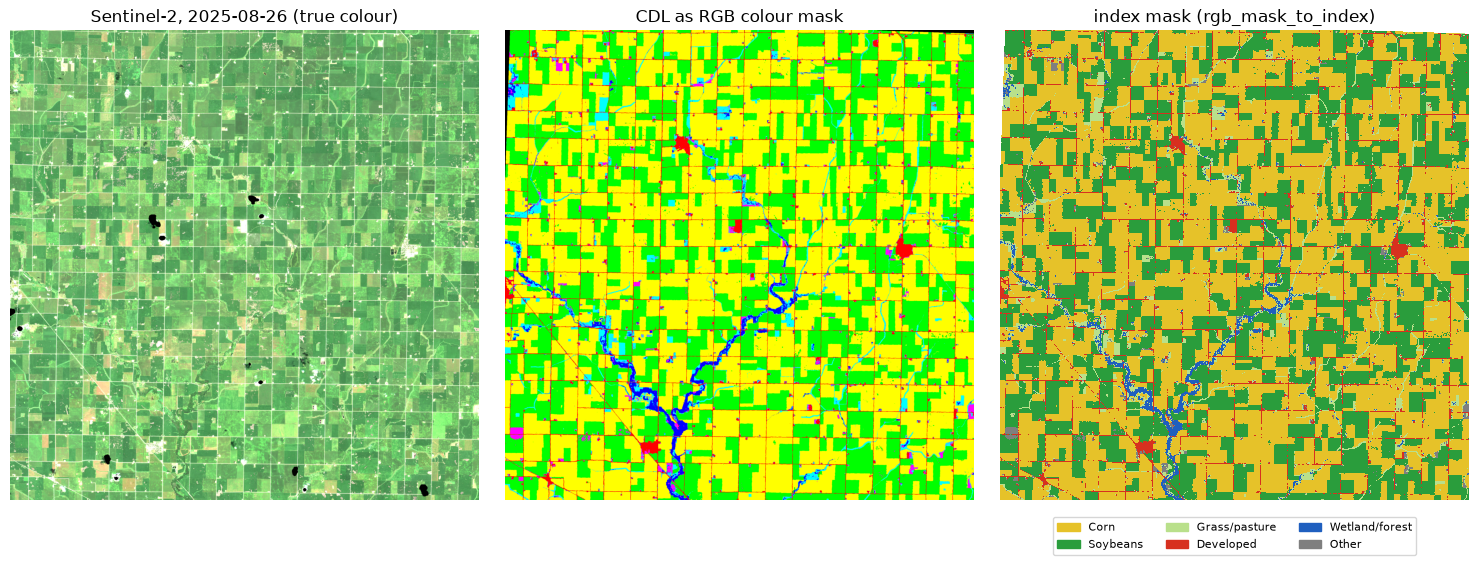

In [3]:
# CDL on the 10 m grid (nearest neighbour)
cdl = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True).rio.reproject_match(ref, resampling=0)
cdl = cdl.isel(y=slice(0, N), x=slice(0, N)).values.astype(int)  # cropped to the working area
code_map = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4}  # CDL code -> class id
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
# class colours as RGB triples
RGB = [(230, 194, 41), (42, 157, 60), (185, 224, 139), (215, 48, 31), (31, 95, 191), (127, 127, 127)]
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # colour map for the classes
lab_true = np.full(cdl.shape, 5, "int16")  # everything else is "Other" (5)
for k, v in code_map.items():  # each mapped CDL code ...
    lab_true[cdl == k] = v  # ... gets its class id
lab_true[cdl == 0] = -1                                    # background

# cube-corner colours (required by rgb_mask_to_index) and the colour mask
corner = {0: (255, 255, 0), 1: (0, 255, 0), 2: (0, 255, 255), 3: (255, 0, 0), 4: (0, 0, 255), 5: (255, 0, 255)}
cmask = np.zeros(lab_true.shape + (3,), "uint8")           # black = unknown
for i, col in corner.items():  # each class ...
    cmask[lab_true == i] = col  # ... painted in its corner colour
tmp = Path(tempfile.mkdtemp(prefix="seg_legend_"))  # temporary folder for the class table
# write the class table as CSV
pd.DataFrame([(n, *corner[i]) for i, n in enumerate(CLASSES)], columns=["name", "r", "g", "b"]).to_csv(tmp / "classes.csv", index=False)
names, colors = ic.read_class_dict(tmp / "classes.csv")  # read it back: names and colours
lab = ic.rgb_mask_to_index(cmask, colors, unknown=-100)  # colour mask -> class indices
# shapes and class names
print("colour mask", cmask.shape, "-> index mask", lab.shape, "| classes in legend:", names)
# the round trip reproduces the labels
print("round trip equals recoded CDL:", bool((lab[lab_true >= 0] == lab_true[lab_true >= 0]).all()),
      "| unknown/background pixels ->", int((lab == -100).sum()))
# share of each class
share = pd.Series(lab[lab >= 0]).value_counts(normalize=True).sort_index().reindex(range(K))
# shown as a table
print(pd.DataFrame({"class": CLASSES, "pixel share": share.round(4).values}).to_string(index=False))

def rgb(a, lo=0.0, hi=0.07):  # true-colour image for display
    # red, green, blue with the band axis last
    im = np.moveaxis(a.sel(band=["red", "green", "blue"]).values, 0, -1)
    return np.clip((np.nan_to_num(im) - lo) / (hi - lo), 0, 1) ** 0.8  # stretch, clip and brighten slightly
sh = lambda a: np.where(a < 0, np.nan, a)  # negative ids become missing for plotting
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))  # three panels
ax[0].imshow(rgb(refl)); ax[0].set_title("Sentinel-2, 2025-08-26 (true colour)")  # true colour
ax[1].imshow(cmask); ax[1].set_title("CDL as RGB colour mask")  # colour mask
# index mask
ax[2].imshow(sh(lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("index mask (rgb_mask_to_index)")
for a in ax: a.axis("off")  # no axes
# class legend
ax[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.13))
plt.tight_layout(); plt.show()  # arrange and draw

## Patch sampling, spatial split and normalisation

A $2816\times2816$ raster with 10 bands does not fit through a network at once, so the network is trained on **patches** of $128\times128$ px (1.28 km). Patches are cut **inside** 256 px blocks:

* training and validation patches: stride 64 px (50 % overlap, 9 patches per block), which acts as extra sampling;
* test patches: stride 128 px, i.e. 4 non-overlapping patches per block that tile the test blocks exactly.

**Blocks are split first, patches are cut second**, so no pixel appears in two splits. `group_split` assigns the 121 block ids 60/20/20 and `check_split_isolation` verifies it. Pixels without a valid label (background or cloud) get the ignore index $-100$ and are excluded from the loss and from the metrics. The `Normalizer` is fitted (NaN-aware) on the **training patches only**.


blocks train/val/test = 73/24/24 - isolation check passed
patches: train 657 | val 216 | test 96 (128x128 px, 10 bands) | train tensor 0.43 GB
                 train     val    test
Corn            0.5210  0.5761  0.5049
Soybeans        0.3645  0.3315  0.3955
Grass/pasture   0.0429  0.0333  0.0337
Developed       0.0481  0.0416  0.0424
Wetland/forest  0.0136  0.0062  0.0171
Other           0.0099  0.0113  0.0064


batch: {'image': ((16, 10, 128, 128), 'torch.float32'), 'mask': ((16, 128, 128), 'torch.int64')}


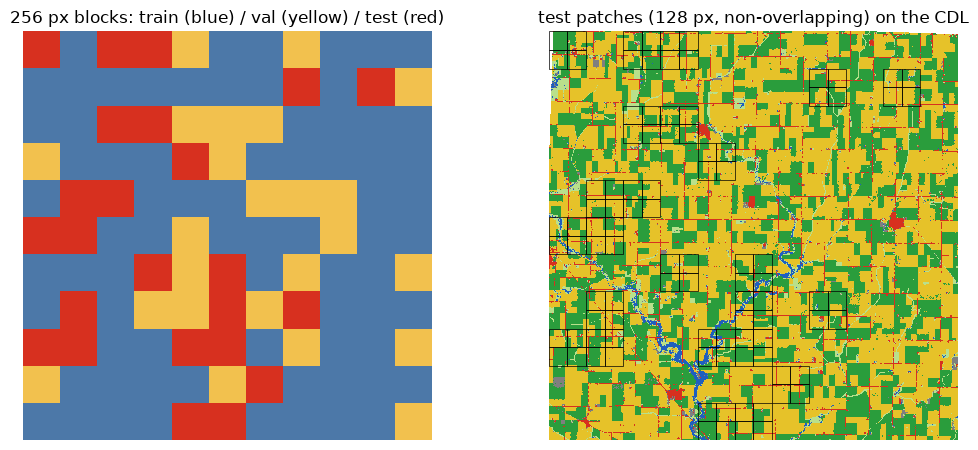

In [4]:
PS = 128  # patch size in pixels
X_all, Y_all = refl.values, np.where(np.isnan(refl.values[0]), -100, lab).astype("int64")   # NaN reflectance -> ignore
def sample_patches(block_ids, stride):  # cut patches from the given blocks with a given stride
    xs, ys, bid, pos = [], [], [], []  # patches, masks, block ids and positions
    for b in block_ids:  # each block
        bi, bj = divmod(int(b), nb)  # its row and column in the block grid
        for r in range(bi * BLOCK, (bi + 1) * BLOCK - PS + 1, stride):  # patch rows inside the block
            for c in range(bj * BLOCK, (bj + 1) * BLOCK - PS + 1, stride):  # patch columns inside the block
                # keep the patch, its mask, block and position
                xs.append(X_all[:, r:r + PS, c:c + PS]); ys.append(Y_all[r:r + PS, c:c + PS]); bid.append(b); pos.append((r, c))
    return np.stack(xs), np.stack(ys), np.array(bid), np.array(pos)  # as arrays

# 60 / 20 / 20 split of the blocks
sp = ic.group_split(np.arange(nb * nb), test_size=0.2, val_size=0.2, seed=SEED)
ic.check_split_isolation(train=sp.train, val=sp.val, test=sp.test)  # no block in two splits
Xtr, Ytr, btr, _ = sample_patches(sp.train, 64)  # overlapping training patches (stride 64)
Xva, Yva, bva, _ = sample_patches(sp.val, 64)  # overlapping validation patches
Xte, Yte, bte, pte = sample_patches(sp.test, 128)  # non-overlapping test patches
keep = (Ytr >= 0).mean((1, 2)) >= 0.5                       # drop mostly-invalid training patches
Xtr, Ytr, btr = Xtr[keep], Ytr[keep], btr[keep]  # apply that filter
# block counts
print(f"blocks train/val/test = {len(sp.train)}/{len(sp.val)}/{len(sp.test)} - isolation check passed")
# patch counts and shapes
print(f"patches: train {len(Xtr)} | val {len(Xva)} | test {len(Xte)} ({PS}x{PS} px, {len(BANDS)} bands) | train tensor {Xtr.nbytes/1e9:.2f} GB")
# class shares per split
cnt = pd.DataFrame({s: np.bincount(Y[Y >= 0], minlength=K) / (Y >= 0).sum() for s, Y in [("train", Ytr), ("val", Yva), ("test", Yte)]}, index=CLASSES)
print(cnt.round(4))  # show them

norm = ic.Normalizer("zscore").fit(Xtr, band_axis=1)  # per-band z-score fitted on the training patches
# patch dataset with the normaliser
mk = lambda X, Y, tf=None: ic.ChipDataset(X, Y, normalizer=norm, transform=tf)
ld_va = ic.as_loader(mk(Xva, Yva), 32, shuffle=False)  # validation batches
ld_te = ic.as_loader(mk(Xte, Yte), 32, shuffle=False)  # test batches
b = next(iter(ic.as_loader(mk(Xtr, Ytr), 16, shuffle=True, seed=SEED)))  # one shuffled training batch
print("batch:", {k: (tuple(v.shape), str(v.dtype)) for k, v in b.items()})  # its tensors

# split of every block (0 train, 1 val, 2 test)
bsplit = np.full(nb * nb, np.nan); bsplit[sp.train] = 0; bsplit[sp.val] = 1; bsplit[sp.test] = 2
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))  # two panels
ax[0].imshow(bsplit.reshape(nb, nb), cmap=ListedColormap(["#4c78a8", "#f2c14e", "#d7301f"]), interpolation="nearest")
ax[0].set_title("256 px blocks: train (blue) / val (yellow) / test (red)")  # title
ax[1].imshow(sh(lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")  # the CDL
# outline every test patch
for (r, c) in pte: ax[1].add_patch(plt.Rectangle((c, r), PS, PS, fill=False, ec="k", lw=0.5))
ax[1].set_title("test patches (128 px, non-overlapping) on the CDL")  # title
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## Segmentation architectures and the mathematics behind them

`build_segmenter(arch, in_channels, num_classes, encoder="resnet34", weights=None, first_conv="mean", **kwargs)` returns a network with **logits of shape $(N,K,H,W)$**: the first layer is rebuilt for $C=10$ bands (with `weights="imagenet"` the RGB filters are averaged and replicated over the extra bands). Here every model is trained from scratch.

| Family | `arch` | Core idea |
|---|---|---|
| FCN | `fcn_resnet50`, `fcn_resnet101` | convolutionalise a classifier, upsample the coarse score map |
| U-Net | `unet`, `unet_basic`, `unetplusplus` | symmetric encoder-decoder with skip concatenation |
| DeepLabV3 | `deeplabv3_resnet50`, `deeplabv3_mobilenet` | atrous (dilated) convolution + ASPP |
| DeepLabV3+ | `deeplabv3plus` | ASPP encoder + light decoder with low-level features |
| SegFormer | `segformer` | hierarchical transformer encoder + all-MLP decoder |

### Shared notation
A convolution with kernel $k$, stride $s$, padding $p$ maps an $H\times W$ map to

$$H'=\Big\lfloor\frac{H+2p-k}{s}+1\Big\rfloor,\qquad Z_o(i,j)=b_o+\sum_{c=1}^{C_{in}}\sum_{u,v=0}^{k-1}W_{o,c}(u,v)\,A_c(si+u-p,\,sj+v-p).$$

Encoders **downsample** by an *output stride* $S$ (the feature map is $H/S\times W/S$), which enlarges the receptive field but loses detail; segmentation heads must **restore** the resolution. A transposed convolution (stride $s$) or bilinear interpolation upsamples by $s$. The class probabilities are the pixel-wise softmax $p_k(i,j)=e^{Z_k(i,j)}/\sum_m e^{Z_m(i,j)}$.


### FCN: fully convolutional networks (`fcn_resnet50`, `fcn_resnet101`)
A classifier ends with a fully connected layer $\mathbf s=W\mathbf h+\mathbf b$ on the flattened features. Writing $W$ as a $1\times1$ **convolution**, $Z_k(i,j)=\sum_c W_{kc}A_c(i,j)+b_k$, turns the same weights into a network that accepts any input size and returns a **coarse score map** $\mathbf Z\in\mathbb R^{K\times H/S\times W/S}$. The map is upsampled to full size, either with a learned transposed convolution or with bilinear interpolation,

$$Z_k^{\uparrow}(i,j)=\sum_{a,b\in\{0,1\}}w_{ab}\,Z_k\big(\lfloor i/S\rfloor+a,\ \lfloor j/S\rfloor+b\big),$$

where $w_{ab}$ are the bilinear weights. The original FCN-32s/16s/8s **fuse** the coarse prediction with finer pooling layers (skip connections, $\mathbf Z=\mathbf Z_{32}^{\uparrow2}+\mathbf Z_{16}$, ...) to recover detail. The torchvision `fcn_resnet50` uses a ResNet-50 backbone with **dilated** convolutions in the last two stages (output stride $S=8$) and an FCN head $3\times3\ \text{conv}(2048\to512)\to\text{BN}\to\text{ReLU}\to\text{dropout}\to1\times1\ \text{conv}(512\to K)$, followed by bilinear upsampling $\times8$. It has 33 M parameters, dominated by the ResNet backbone. Its weakness: one coarse feature map has to carry both *what* (semantics) and *where* (edges), so boundaries are blurry.


### U-Net (`unet`, `unet_basic`, `unetplusplus`)
U-Net resolves the what/where conflict with an **encoder-decoder** and **skip connections** at every scale. The encoder halves the resolution $L$ times while doubling the channels; the decoder mirrors it:

$$\mathbf e_{l}=\mathrm{Enc}_l(\mathbf e_{l-1}),\qquad \mathbf d_{l}=\mathrm{Conv}\Big(\big[\,\mathrm{Up}(\mathbf d_{l+1})\ \|\ \mathbf e_{l}\,\big]\Big),$$

where $\mathrm{Up}$ doubles the resolution (a $2\times2$ transposed convolution or bilinear upsampling plus $3\times3$ convolution), $[\cdot\|\cdot]$ is **channel concatenation** and $\mathrm{Conv}$ is two $3\times3$ convolution + BN + ReLU. The high-resolution encoder features $\mathbf e_l$ carry the **location** detail (edges, thin objects) and the upsampled decoder features carry the **semantics**; their concatenation lets the final $1\times1$ convolution $\mathbf Z=W\mathbf d_0$ produce sharp boundaries. `unet_basic` is the plain-PyTorch U-Net (7.8 M parameters); `unet` uses a ResNet encoder from *segmentation-models-pytorch* (here `resnet18`, 14 M parameters), and `unetplusplus` adds dense nested skip paths $\mathbf x^{i,j}=\mathrm{Conv}([\mathbf x^{i,0},\dots,\mathbf x^{i,j-1},\mathrm{Up}(\mathbf x^{i+1,j-1})])$. U-Net is data efficient, which is why it dominates remote-sensing segmentation with small training sets.


### DeepLabV3 (`deeplabv3_resnet50`, `deeplabv3_mobilenet`)
DeepLab keeps the resolution of the feature map high without losing the receptive field by using **atrous (dilated) convolution**: a $k\times k$ kernel with rate $r$ samples the input every $r$ pixels,

$$y(i,j)=\sum_{u,v=0}^{k-1}W(u,v)\,x(i+r\,u,\ j+r\,v),\qquad k_{\text{eff}}=k+(k-1)(r-1).$$

A $3\times3$ kernel with $r=6$ covers $13\times13$ pixels with only 9 weights, so the encoder can keep output stride $S=8$ or $16$ instead of 32. Objects occur at different scales, so DeepLabV3 applies **Atrous Spatial Pyramid Pooling (ASPP)**: parallel branches on the same feature map $\mathbf F$,

$$\mathrm{ASPP}(\mathbf F)=W_{1\times1}\Big[\,\mathrm{C}_{1\times1}(\mathbf F)\ \|\ \mathrm{C}^{r_1}_{3\times3}(\mathbf F)\ \|\ \mathrm{C}^{r_2}_{3\times3}(\mathbf F)\ \|\ \mathrm{C}^{r_3}_{3\times3}(\mathbf F)\ \|\ \mathrm{Up}(\mathrm{GAP}(\mathbf F))\,\Big],$$

with rates such as $(r_1,r_2,r_3)=(12,24,36)$ (for $S=8$), the **global average pooling** branch capturing image-level context, and a $1\times1$ convolution fusing the five concatenated branches. The result is upsampled bilinearly $\times S$. DeepLabV3 therefore sees context at several scales at once, but its final upsampling is a plain interpolation, so it is *not* a sharp boundary delineator. With a ResNet-50 backbone it has 40 M parameters; the MobileNet-v3 variant has 11 M.


### DeepLabV3+ (`deeplabv3plus`)
DeepLabV3+ adds a small **decoder** to DeepLabV3 to repair the boundaries. The ASPP output (stride $S=16$) is upsampled $\times4$ and concatenated with **low-level features** $\mathbf F_{low}$ from an early encoder stage (stride 4), reduced to 48 channels by a $1\times1$ convolution so that they do not overwhelm the semantic features:

$$\mathbf d=\mathrm{Conv}_{3\times3}\Big(\big[\,\mathrm{Up}_{4}(\mathrm{ASPP}(\mathbf F))\ \|\ W_{1\times1}\mathbf F_{low}\,\big]\Big),\qquad \mathbf Z=\mathrm{Up}_{4}\big(W_{cls}\,\mathbf d\big).$$

It also uses **depth-wise separable convolutions** in ASPP and the decoder: a depth-wise $k\times k$ convolution (one filter per channel) followed by a point-wise $1\times1$ convolution costs $k^2C_{in}+C_{in}C_{out}$ instead of $k^2C_{in}C_{out}$ multiply-adds per pixel. Compared with U-Net it has only **one** skip connection (stride 4) rather than one per scale, and compared with DeepLabV3 it keeps the multi-scale context while sharpening edges. Here `encoder="resnet18"` gives 12 M parameters.


### SegFormer (`segformer`)
SegFormer replaces the convolutional encoder by a **hierarchical Mix Transformer (MiT)** and the decoder by a few linear layers.

**Overlapping patch embedding.** Each stage cuts its input into *overlapping* patches ($7\times7$, stride 4 in stage 1; $3\times3$, stride 2 in later stages) and projects them to $C_i$ channels, giving a pyramid of feature maps at strides $4,8,16,32$ with widths $(C_1,\dots,C_4)=(32,64,160,256)$ for `mit_b0`.

**Efficient self-attention.** Standard attention over $N=HW/S^2$ tokens costs $O(N^2)$. SegFormer **reduces the sequence** of keys and values by a ratio $R$ (a strided reshape + linear layer, $\mathbf K\to\mathbf K'\in\mathbb R^{\frac NR\times C}$):

$$\mathrm{Attn}(\mathbf Q,\mathbf K',\mathbf V')=\mathrm{softmax}\!\Big(\frac{\mathbf Q\mathbf K'^{\top}}{\sqrt{d_k}}\Big)\mathbf V',\qquad \text{cost }O\!\Big(\frac{N^2}{R}\Big).$$

**Mix-FFN** replaces positional encodings by a $3\times3$ depth-wise convolution inside the feed-forward block, $\mathbf x_{out}=\mathrm{MLP}\big(\mathrm{GELU}(\mathrm{Conv}_{3\times3}(\mathrm{MLP}(\mathbf x_{in})))\big)+\mathbf x_{in}$, so the model does not depend on the input size (no interpolated position embeddings).

**All-MLP decoder.** The four multi-scale maps $\mathbf F_i$ are each projected to a common width $C$ by a linear layer, upsampled to stride 4, concatenated, fused and classified:

$$\hat{\mathbf F}_i=\mathrm{Up}_{4/S_i}\big(W_i\mathbf F_i\big),\qquad \mathbf Z=W_{cls}\ \mathrm{Linear}\big([\hat{\mathbf F}_1\|\hat{\mathbf F}_2\|\hat{\mathbf F}_3\|\hat{\mathbf F}_4]\big).$$

Low stages give local detail and high stages give global context, and the decoder needs no heavy convolutions. `mit_b0` has only 3.7 M parameters, but, like all transformers, it needs more data than small convolutional nets and its output (stride 4) is upsampled by interpolation.


### Comparison and what the architectures share
* **Encoder-decoder pattern.** All models downsample for context and then restore resolution; they differ in *how much detail* is carried back: nothing (FCN, DeepLabV3), one early feature level (DeepLabV3+), all levels (U-Net), or multi-scale features fused by an MLP (SegFormer).
* **Receptive field vs. resolution.** Dilated convolutions (FCN, DeepLab) and attention (SegFormer) enlarge the context without more pooling.
* **Thin classes** (roads, rivers) need the high-resolution skip paths of U-Net and DeepLabV3+; coarse-output models smear them.
* **Cost.** From 3.7 M (SegFormer-b0) to 40 M (DeepLabV3-ResNet50) parameters; the timing table below measures the actual GPU cost for $16\times10\times128\times128$ batches.


In [5]:
# seven segmentation architectures and their options
ARCHS = [("unet_basic", {}), ("unet", {"encoder": "resnet18"}), ("fcn_resnet50", {}), ("deeplabv3_resnet50", {}),
         ("deeplabv3_mobilenet", {}), ("deeplabv3plus", {"encoder": "resnet18"}), ("segformer", {"encoder": "mit_b0"})]
# display names
LABEL = {"unet_basic": "U-Net (basic)", "unet": "U-Net (ResNet-18)", "fcn_resnet50": "FCN (ResNet-50)",
         "deeplabv3_resnet50": "DeepLabV3 (ResNet-50)", "deeplabv3_mobilenet": "DeepLabV3 (MobileNetV3)",
         "deeplabv3plus": "DeepLabV3+ (ResNet-18)", "segformer": "SegFormer (MiT-b0)"}
x = torch.randn(16, len(BANDS), PS, PS).to(DEVICE); rows = []  # a random batch of 16 patches; result rows
for a, kw in ARCHS:  # each architecture
    m = ic.build_segmenter(a, in_channels=len(BANDS), num_classes=K, **kw).to(DEVICE)  # build it on the device
    # optimiser; logits have the expected shape
    opt = torch.optim.AdamW(m.parameters()); out = m(x); assert out.shape == (16, K, PS, PS)
    if DEVICE == "cuda": torch.cuda.synchronize()  # wait for the GPU before timing
    t0 = time.time()  # start the timer
    for _ in range(5):  # five training steps
        opt.zero_grad(); m(x).mean().backward(); opt.step()  # one step
    if DEVICE == "cuda": torch.cuda.synchronize()  # wait for the GPU
    # size and time per step
    rows.append({"model": LABEL[a], "arch": a, "parameters": ic.count_parameters(m), "ms / train step (16x128x128)": (time.time() - t0) / 5 * 1000})
    del m, opt  # free memory
arch_tab = pd.DataFrame(rows).set_index("arch").round(1)  # as a table
print("every model returns logits of shape", tuple(out.shape))  # output shape
arch_tab  # show it

every model returns logits of shape (16, 6, 128, 128)


,model,parameters,ms / train step (16x128x128)
arch,,,
unet_basic,U-Net (basic),7765222,66.2
unet,U-Net (ResNet-18),14350886,24.3
fcn_resnet50,FCN (ResNet-50),32971270,69.6
deeplabv3_resnet50,DeepLabV3 (ResNet-50),39656966,80.4
deeplabv3_mobilenet,DeepLabV3 (MobileNetV3),11022630,19.1
deeplabv3plus,DeepLabV3+ (ResNet-18),12352534,17.2
segformer,SegFormer (MiT-b0),3726662,53.3


## Segmentation losses: Dice, Lovász and focal versus cross-entropy

Let $p_{ik}$ be the softmax probability of class $k$ at pixel $i$, $y_{ik}\in\{0,1\}$ the one-hot reference and $N_{\text{valid}}$ the number of non-ignored pixels. `get_loss(name, class_weights=, gamma=, label_smoothing=)` returns:

* **Cross-entropy** $\;\mathcal L_{CE}=-\frac1{N}\sum_i\log p_{i,y_i}$.
* **Weighted CE** $\;\mathcal L_{WCE}=-\frac1{N}\sum_i w_{y_i}\log p_{i,y_i}$ with $w_k$ from `class_weights` (here $\propto1/\sqrt{\pi_k}$).
* **Focal** (Lin et al.) $\;\mathcal L_{F}=-\frac1{N}\sum_i(1-p_{i,y_i})^{\gamma}\log p_{i,y_i}$, which down-weights pixels that are already easy.
* **Soft Dice** $\;\mathcal L_{Dice}=1-\frac1{K}\sum_{k}\frac{2\sum_ip_{ik}y_{ik}+s}{\sum_ip_{ik}+\sum_iy_{ik}+s}$, the differentiable form of the F1 score computed **per class over the whole batch**.
* **Lovász-softmax** (Berman et al.) a convex *surrogate of the Jaccard index* (IoU). For class $k$ with pixel errors $m_i=|y_{ik}-p_{ik}|$ sorted in decreasing order, $\mathcal L_{Lov}=\frac1K\sum_k\sum_i m_{(i)}\,\Delta_{J_k}(i)$ with the increments $\Delta_{J_k}(i)=J_k(i)-J_k(i-1)$ of the Jaccard loss $J_k(S)=1-\frac{|\{y=k\}\cap S|}{|\{y=k\}\cup S|}$ over the first $i$ sorted errors. It optimises mIoU directly.
* **CE + Dice** $\;\mathcal L=\mathcal L_{CE}+\mathcal L_{Dice}$: pixel-wise gradients of CE plus the class-balanced overlap of Dice.

### Why CE alone under-weights thin classes
Write the CE as a sum over classes with $\pi_k$ the pixel share of class $k$ and $\bar\ell_k$ the mean loss of its pixels:

$$\mathcal L_{CE}=\sum_{k=1}^{K}\pi_k\,\bar\ell_k .$$

A class with $\pi_k=1\,\%$ (rivers, roads, small towns) contributes at most 1 % of the total loss and of the gradient, so the optimiser can ignore it: misclassifying *all* its pixels as the neighbouring corn costs about $\pi_k\log(1/\epsilon)$, a small price, while mIoU gives that class the **same weight** as corn, $\mathrm{mIoU}=\frac1K\sum_k\mathrm{IoU}_k$. Thin objects make it worse because most of their pixels sit on a boundary where the prediction is blurred. Dice and Lovász normalise **per class** ($\sum_i y_{ik}$ is in the denominator), so every class weighs $1/K$ irrespective of its size, and class weights in WCE achieve the same by reweighting. The experiments in the *Loss ablation: thin classes and mIoU* section measure this.


In [6]:
# square-root inverse class weights from the training pixels
CW = ic.class_weights(Ytr[Ytr >= 0], num_classes=K, method="sqrt_inverse")
# class shares and weights
print(pd.DataFrame({"pixel share (train)": cnt["train"].values, "weight sqrt-inverse": CW}, index=CLASSES).round(4))
# a thin class barely moves the CE: all Developed pixels wrong vs. all Corn pixels wrong
zb = torch.zeros(1, K, 1, 1) + torch.tensor([1.0, 0, 0, 0, 0, 0]).view(1, K, 1, 1) * 4  # confident in 'Corn'
for k in (0, 3):  # a Corn pixel and a Developed pixel
    t = torch.full((1, 1, 1), k)  # one pixel of that class
    # its cross-entropy
    print(f"single pixel of class {CLASSES[k]:9s}: CE = {float(ic.get_loss('ce')(zb, t)):.3f}")
pi = cnt["train"].values  # training class shares
# share of the loss each class contributes
print("share of the CE gradient mass if every class has the same per-pixel loss:", dict(zip(CLASSES, (pi / pi.sum()).round(3))))

                pixel share (train)  weight sqrt-inverse
Corn                         0.5210               0.2676
Soybeans                     0.3645               0.3199
Grass/pasture                0.0429               0.9324
Developed                    0.0481               0.8802
Wetland/forest               0.0136               1.6564
Other                        0.0099               1.9436
single pixel of class Corn     : CE = 0.088
single pixel of class Developed: CE = 4.088
share of the CE gradient mass if every class has the same per-pixel loss: {'Corn': np.float64(0.521), 'Soybeans': np.float64(0.364), 'Grass/pasture': np.float64(0.043), 'Developed': np.float64(0.048), 'Wetland/forest': np.float64(0.014), 'Other': np.float64(0.01)}


## Training with `train_model`: architecture benchmark

`train_model(model, train_loader, val_loader, task="segmentation", epochs, loss, optimizer, lr, scheduler, precision, grad_clip, early_stopping, monitor, checkpoint, num_classes, ignore_index, ...)` is the same explicit PyTorch loop used for chip classification, with the **validation score equal to mIoU** for `task="segmentation"`. We use AdamW, a cosine schedule, mixed precision (AMP) and gradient clipping, and train every architecture with **the same recipe** (plain CE, dihedral augmentation) for 20 epochs over three seeds, reporting the mean $\pm$ SD of the test mIoU on the held-out blocks.

* **AdamW:** $\theta\leftarrow\theta-\eta\Big(\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta\Big)$;  **cosine schedule:** $\eta_t=\tfrac12\eta_0\big(1+\cos(\pi t/T)\big)$;
* **Gradient clipping:** $\mathbf g\leftarrow\mathbf g\,\min(1,c/\lVert\mathbf g\rVert_2)$.
* **Augmentation:** `OverheadAugment(dihedral=True)` applies the same random rotation/flip (8 elements of the dihedral group $D_4$; overhead imagery has no "up") to **image and mask**.

The helper below trains one model and scores the test patches with `segmentation_metrics`.


In [7]:
def score(pred, target):  # mIoU, accuracy and per-class IoU/F1 ...
    # ... ignoring -100 pixels
    return ic.segmentation_metrics(pred, target, num_classes=K, ignore_index=-100, class_names=CLASSES)

# train one segmenter and score it on the test patches
def fit(arch, *, kw=None, seed=0, epochs=EPOCHS, loss="ce", lr=1e-3, aug=True, early=None, checkpoint=None, logger=None, log_dir=None):
    ic.set_seed(seed)  # same initial weights for a given seed
    # optional rotation and flip augmentation
    tf = ic.OverheadAugment(dihedral=True, p=1.0, seed=seed) if aug else None
    # shuffled training batches
    ltr = ic.as_loader(mk(Xtr, Ytr, tf), 16, shuffle=True, seed=seed, drop_last=True)
    model = ic.build_segmenter(arch, in_channels=len(BANDS), num_classes=K, **(kw or {}))  # the segmenter
    # the loss (with class weights where used)
    lf = ic.get_loss(loss, class_weights=CW if loss in ("weighted_ce", "focal") else None)
    t0 = time.time()  # start the timer
    # the GeoLattice training loop in segmentation mode
    hist = ic.train_model(model, ltr, ld_va, task="segmentation", epochs=epochs, loss=lf, optimizer="adamw", lr=lr, weight_decay=1e-4,
                          scheduler="cosine", precision="16" if DEVICE == "cuda" else "32", grad_clip=1.0, early_stopping=early,
                          monitor="val_score", checkpoint=checkpoint, seed=seed, num_classes=K, logger=logger, log_dir=log_dir,
                          device=DEVICE, verbose=False)
    sec = time.time() - t0  # training time
    Pt = ic.predict_proba_batches(model, ld_te, device=DEVICE)  # test probabilities
    m = score(Pt.argmax(1), Yte)  # test scores
    # model, history and scores
    return dict(model=model, hist=hist, sec=sec, val_miou=float(max(hist["val_score"])), test_miou=m["miou"], oa=m["pixel_accuracy"],
                f1=m["per_class"]["dice"].values, iou=m["per_class"]["iou"].values)

In [8]:
res, rows = {}, []  # trained runs and result rows
for a, kw in ARCHS:  # each architecture
    for s in SEEDS:  # each seed
        r = fit(a, kw=kw, seed=s); res[(a, s)] = r  # train and keep it
        # its scores
        rows.append(dict(arch=a, seed=s, val_miou=r["val_miou"], test_miou=r["test_miou"], pixel_acc=r["oa"], sec=r["sec"]))
    d = pd.DataFrame(rows).query("arch == @a")  # runs of this architecture
    # progress line
    print(f"{LABEL[a]:26s} val mIoU {d.val_miou.mean():.3f} | test mIoU {d.test_miou.mean():.3f} ± {d.test_miou.std():.3f} | {d.sec.mean():.0f}s/run")
bench = pd.DataFrame(rows)  # as a table
# mean and spread per architecture
tab = bench.groupby("arch", sort=False).agg(val_miou=("val_miou", "mean"), test_miou=("test_miou", "mean"), test_sd=("test_miou", "std"),
                                            pixel_acc=("pixel_acc", "mean"), sec=("sec", "mean"))
# add size and display names
tab.insert(0, "parameters", arch_tab["parameters"]); tab.insert(0, "model", [LABEL[a] for a in tab.index])
tab.round(4)  # show it

U-Net (basic)              val mIoU 0.615 | test mIoU 0.651 ± 0.003 | 27s/run


U-Net (ResNet-18)          val mIoU 0.605 | test mIoU 0.630 ± 0.006 | 23s/run


FCN (ResNet-50)            val mIoU 0.552 | test mIoU 0.582 ± 0.001 | 47s/run


DeepLabV3 (ResNet-50)      val mIoU 0.545 | test mIoU 0.571 ± 0.000 | 53s/run


DeepLabV3 (MobileNetV3)    val mIoU 0.403 | test mIoU 0.427 ± 0.017 | 28s/run


DeepLabV3+ (ResNet-18)     val mIoU 0.576 | test mIoU 0.604 ± 0.003 | 21s/run


SegFormer (MiT-b0)         val mIoU 0.576 | test mIoU 0.605 ± 0.003 | 31s/run


,model,parameters,val_miou,test_miou,test_sd,pixel_acc,sec
arch,,,,,,,
unet_basic,U-Net (basic),7765222,0.6148,0.6512,0.0032,0.9525,26.7020
unet,U-Net (ResNet-18),14350886,0.6053,0.6302,0.0062,0.9489,23.0207
fcn_resnet50,FCN (ResNet-50),32971270,0.5520,0.5824,0.0015,0.9360,47.0513
deeplabv3_resnet50,DeepLabV3 (ResNet-50),39656966,0.5447,0.5711,0.0004,0.9341,52.7749
deeplabv3_mobilenet,DeepLabV3 (MobileNetV3),11022630,0.4033,0.4270,0.0173,0.8993,28.1968
deeplabv3plus,DeepLabV3+ (ResNet-18),12352534,0.5759,0.6037,0.0035,0.9425,21.1417
segformer,SegFormer (MiT-b0),3726662,0.5763,0.6049,0.0028,0.9440,30.8691


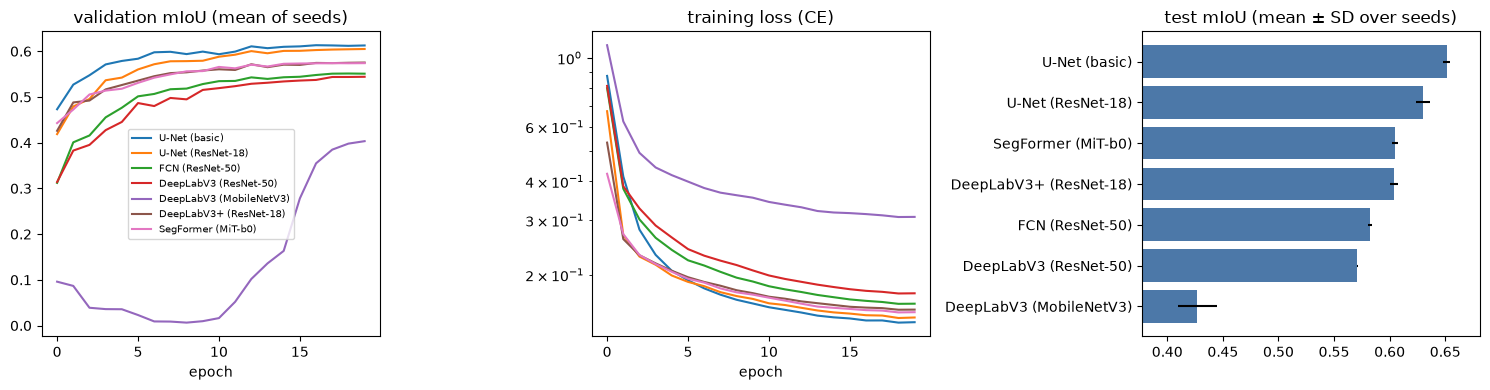

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))  # three panels
for a, _ in ARCHS:  # each architecture
    # mean validation mIoU over seeds
    h = np.mean([res[(a, s)]["hist"]["val_score"] for s in SEEDS], 0); ax[0].plot(h, label=LABEL[a])
    # mean training loss
    ax[1].plot(np.mean([res[(a, s)]["hist"]["train_loss"] for s in SEEDS], 0), label=LABEL[a])
# titles and log scale
ax[0].set_title("validation mIoU (mean of seeds)"); ax[1].set_title("training loss (CE)"); ax[1].set_yscale("log"); ax[0].legend(fontsize=7)
for a in ax[:2]: a.set_xlabel("epoch")  # epoch axes
t = tab.sort_values("test_miou")  # sorted by test mIoU
ax[2].barh(t["model"], t["test_miou"], xerr=t["test_sd"], color="#4c78a8"); ax[2].set_xlim(t["test_miou"].min() - 0.05, t["test_miou"].max() + 0.03)
ax[2].set_title("test mIoU (mean ± SD over seeds)")  # title
plt.tight_layout(); plt.show()  # arrange and draw

## Loss ablation: thin classes and mIoU

The U-Net with a ResNet-18 encoder is retrained with each loss of the *Segmentation losses: Dice, Lovász and focal versus cross-entropy* section, three seeds each, everything else fixed. Besides mIoU we show the **per-class IoU**, because the point of the Dice, Lovász and weighted losses is the small classes, which hardly change the pixel accuracy. The mean IoU is over all six classes; a class absent from the test blocks would be $\mathrm{NaN}$ and is skipped.


In [10]:
LOSSES = ["ce", "weighted_ce", "focal", "dice", "lovasz", "ce+dice"]  # six losses
rows, iou_rows = [], []  # overall and per-class rows
for lo in LOSSES:  # each loss
    for s in SEEDS:  # each seed
        r = fit("unet", kw={"encoder": "resnet18"}, seed=s, loss=lo)  # train U-Net (ResNet-18) with this loss
        # its scores
        rows.append(dict(loss=lo, seed=s, val_miou=r["val_miou"], test_miou=r["test_miou"], pixel_acc=r["oa"], macro_f1=np.nanmean(r["f1"])))
        iou_rows.append(dict(loss=lo, seed=s, **dict(zip(CLASSES, r["iou"]))))  # its per-class IoU
    print(lo, "done")  # progress
loss_df = pd.DataFrame(rows)  # as a table
# mean and spread per loss
loss_tab = loss_df.groupby("loss", sort=False).agg(val_miou=("val_miou", "mean"), test_miou=("test_miou", "mean"), test_sd=("test_miou", "std"),
                                                   pixel_acc=("pixel_acc", "mean"), macro_f1=("macro_f1", "mean")).round(4)
print(loss_tab.to_string())  # show it
iou_tab = pd.DataFrame(iou_rows).groupby("loss", sort=False)[CLASSES].mean().round(3)  # mean per-class IoU
print("\nper-class IoU (mean of seeds):"); print(iou_tab.to_string())  # header and table

ce done


weighted_ce done


focal done


dice done


lovasz done


ce+dice done
             val_miou  test_miou  test_sd  pixel_acc  macro_f1
loss                                                          
ce             0.6053     0.6302   0.0062     0.9489    0.7293
weighted_ce    0.5953     0.6249   0.0039     0.9420    0.7308
focal          0.5899     0.6188   0.0013     0.9399    0.7257
dice           0.6006     0.6295   0.0046     0.9451    0.7336
lovasz         0.5804     0.6140   0.0037     0.9418    0.7183
ce+dice        0.6088     0.6362   0.0009     0.9478    0.7405

per-class IoU (mean of seeds):
              Corn  Soybeans  Grass/pasture  Developed  Wetland/forest  Other
loss                                                                         
ce           0.953     0.947          0.545      0.594           0.627  0.115
weighted_ce  0.947     0.944          0.518      0.587           0.596  0.158
focal        0.944     0.942          0.511      0.574           0.588  0.154
dice         0.947     0.942          0.528      0.588       

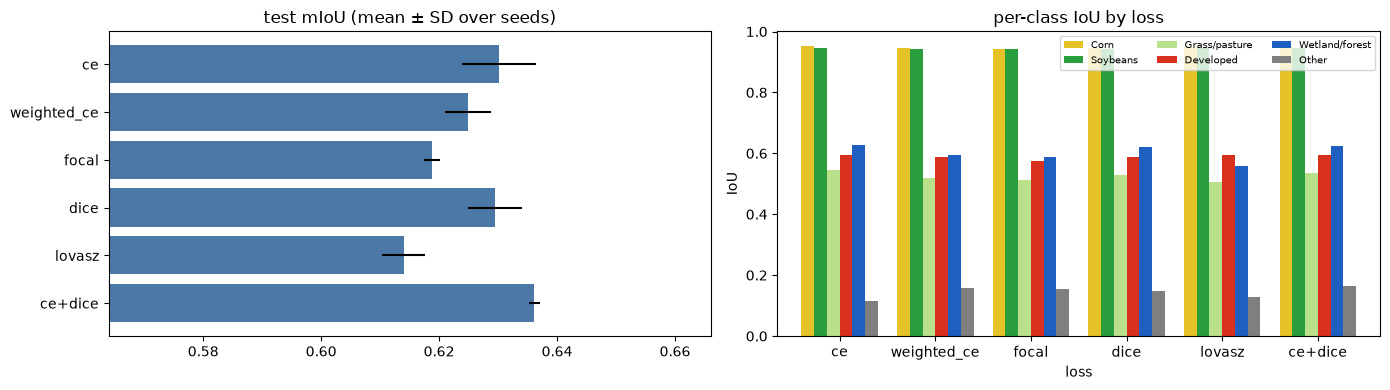

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))  # two panels
g = loss_df.groupby("loss", sort=False)["test_miou"]  # test mIoU per loss
ax[0].barh(range(len(g.mean())), g.mean(), xerr=g.std(), color="#4c78a8"); ax[0].set_yticks(range(len(g.mean()))); ax[0].set_yticklabels(g.mean().index)
# limits, order and title
ax[0].set_xlim(g.mean().min() - 0.05, g.mean().max() + 0.03); ax[0].invert_yaxis(); ax[0].set_title("test mIoU (mean ± SD over seeds)")
# per-class IoU as grouped bars
iou_tab.plot.bar(ax=ax[1], color=COLORS, width=0.8); ax[1].set_ylabel("IoU"); ax[1].set_title("per-class IoU by loss"); ax[1].legend(fontsize=7, ncol=3)
ax[1].tick_params(axis="x", rotation=0)  # flat tick labels
plt.tight_layout(); plt.show()  # arrange and draw

## Final model: checkpoint and reload

The final model combines the architecture with the best **validation** mIoU from the *Training with `train_model`: architecture benchmark* section and the loss with the best validation mIoU from the *Loss ablation: thin classes and mIoU* section (choices are made on validation data only; the test blocks are not used for selection). It is trained longer, with early stopping (patience 8 on validation mIoU) and a best-weights checkpoint, then reloaded with `load_checkpoint` into a freshly built network; a correct round trip reproduces the predictions exactly.


architecture selected on validation mIoU: U-Net (basic) | loss selected on validation mIoU: ce+dice


I0000 00:00:1795645805.090973  101438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795645805.120691  101438 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795645807.606376  101438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


stopped after 32 epochs | best val mIoU 0.6241 | test mIoU 0.6610 | pixel acc 0.9530 | checkpoint 31.1 MB | logger tensorboard


load_state_dict: <All keys matched successfully> | max |p_trained - p_reloaded| = 0.0


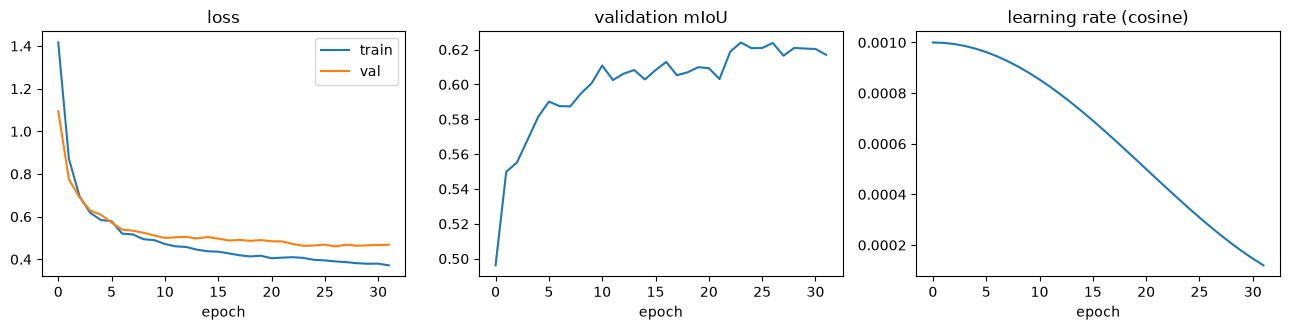

In [12]:
best_arch = tab["val_miou"].idxmax()  # architecture with the best validation mIoU
best_loss = loss_tab["val_miou"].idxmax()  # loss with the best validation mIoU
kw_best = dict(ARCHS)[best_arch]  # options of that architecture
# report the choice
print("architecture selected on validation mIoU:", LABEL[best_arch], "| loss selected on validation mIoU:", best_loss)
# output folder and checkpoint path
OUT = Path(tempfile.mkdtemp(prefix="seg_run_")); CKPT = OUT / "segmenter_best.pt"
try:
    import tensorboard  # noqa
    LOGGER = "tensorboard"  # log to TensorBoard
except ImportError:
    LOGGER = None  # no logger
# train the final model with early stopping and a checkpoint
final = fit(best_arch, kw=kw_best, seed=SEED, epochs=FINAL_EPOCHS, loss=best_loss, early=8, checkpoint=CKPT, logger=LOGGER, log_dir=str(OUT / "tb"))
h = final["hist"]  # its history
# epochs, scores and checkpoint size
print(f"stopped after {len(h['val_score'])} epochs | best val mIoU {max(h['val_score']):.4f} | test mIoU {final['test_miou']:.4f} | pixel acc {final['oa']:.4f} | "
      f"checkpoint {CKPT.stat().st_size/1e6:.1f} MB | logger {LOGGER}")
# a fresh model of the same kind
fresh = ic.build_segmenter(best_arch, in_channels=len(BANDS), num_classes=K, **kw_best)
fresh, missing = ic.load_checkpoint(fresh, CKPT)  # load the saved weights
# probabilities of both models
P1 = ic.predict_proba_batches(final["model"], ld_te, device=DEVICE); P2 = ic.predict_proba_batches(fresh, ld_te, device=DEVICE)
# identical
print("load_state_dict:", missing, "| max |p_trained - p_reloaded| =", float(np.abs(P1 - P2).max()))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))  # three panels
# loss curves
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("loss"); ax[0].legend()
# validation mIoU and learning rate
ax[1].plot(h["val_score"]); ax[1].set_title("validation mIoU"); ax[2].plot(h["lr"]); ax[2].set_title("learning rate (cosine)")
for a in ax: a.set_xlabel("epoch")  # epoch axes
plt.tight_layout(); plt.show()  # arrange and draw

## Large-raster inference: sliding windows, overlap and seam blending

The network was trained on $128\times128$ px patches, but the scene is $2816\times2816$ px. `sliding_window_predict(model, image, tile=, overlap=, normalizer=, blend=, return_proba=, batch_size=, precision=)` cuts the raster into overlapping tiles of `tile` px with stride $T-O$, predicts the softmax probabilities of each tile and **blends** them with a weight window $w(i,j)$:

$$\bar p_k(\mathbf x)=\frac{\sum_{t}w_t(\mathbf x)\,p_{t,k}(\mathbf x)}{\sum_{t}w_t(\mathbf x)},\qquad w(i,j)=w_1(i)\,w_1(j),\quad w_1(i)=\sin^2\!\Big(\frac{\pi i}{T-1}\Big)\ \ (\text{Hann}).$$

**Why:** a convolutional network is least reliable at the **edge of a tile**, where zero padding replaces the missing context, so predictions of adjacent non-overlapping tiles disagree and leave visible *seams*. With overlap, every pixel is predicted several times and the Hann window gives the central, well-informed predictions the largest weight and the unreliable edges almost zero; `triangle` is a linear alternative and `none` averages with equal weights. We compare four settings on the test blocks: no overlap, overlap with uniform weights, triangle and Hann blending. The reference is the same CDL index mask and only valid test-block pixels count.


In [13]:
sub = refl                                                  # the full 2816 x 2816 px working area
blk = np.kron(np.arange(nb * nb).reshape(nb, nb), np.ones((BLOCK, BLOCK), int))  # block id of every pixel
is_te = np.isin(blk, sp.test)  # pixels in test blocks
ref_l = np.where(np.isnan(refl.values[0]), -100, lab)  # reference labels, cloud as ignored
valid = is_te & (ref_l >= 0)  # test pixels with a label

def predict_map(model, overlap, blend, tile=256):  # class map of the working area from sliding tiles
    t0 = time.time()  # start the timer
    # tiled prediction with overlap and blending
    pm = ic.sliding_window_predict(model, sub, tile=tile, overlap=overlap, normalizer=norm, blend=blend, batch_size=8,
                                   device=DEVICE, precision="16" if DEVICE == "cuda" else "32")
    return pm.values.astype(int), time.time() - t0  # map and time

# five tiling settings: overlap and blend
settings = {"no overlap": (0, "none"), "overlap 64, uniform": (64, "none"), "overlap 64, triangle": (64, "triangle"), "overlap 64, Hann": (64, "hann"),
            "overlap 128, Hann": (128, "hann")}
maps, rows = {}, []  # maps and scores
yy, xx = np.mgrid[0:N, 0:N]  # pixel rows and columns
seam = (np.minimum(xx % 256, 256 - xx % 256) < 8) | (np.minimum(yy % 256, 256 - yy % 256) < 8)   # within 8 px of a 256-px tile border
for name, (ov, bl) in settings.items():  # each setting
    pm, sec = predict_map(final["model"], ov, bl); maps[name] = pm  # predict the map
    m = score(pm[valid], ref_l[valid]); e = pm != ref_l  # scores and errors
    # mIoU, accuracy and error near / away from tile borders
    rows.append({"setting": name, "mIoU": m["miou"], "pixel acc": m["pixel_accuracy"], "error near tile borders": e[valid & seam].mean(),
                 "error elsewhere": e[valid & ~seam].mean(), "seconds": sec})
seam_tab = pd.DataFrame(rows).set_index("setting").round(4)  # as a table
seam_tab  # show it

,mIoU,pixel acc,error near tile borders,error elsewhere,seconds
setting,,,,,
no overlap,0.6617,0.9532,0.0536,0.046,0.8823
"overlap 64, uniform",0.6634,0.9535,0.0506,0.046,1.1416
"overlap 64, triangle",0.6636,0.9535,0.0506,0.046,1.1498
"overlap 64, Hann",0.6635,0.9535,0.0506,0.046,1.1418
"overlap 128, Hann",0.6636,0.9535,0.0506,0.046,1.6966


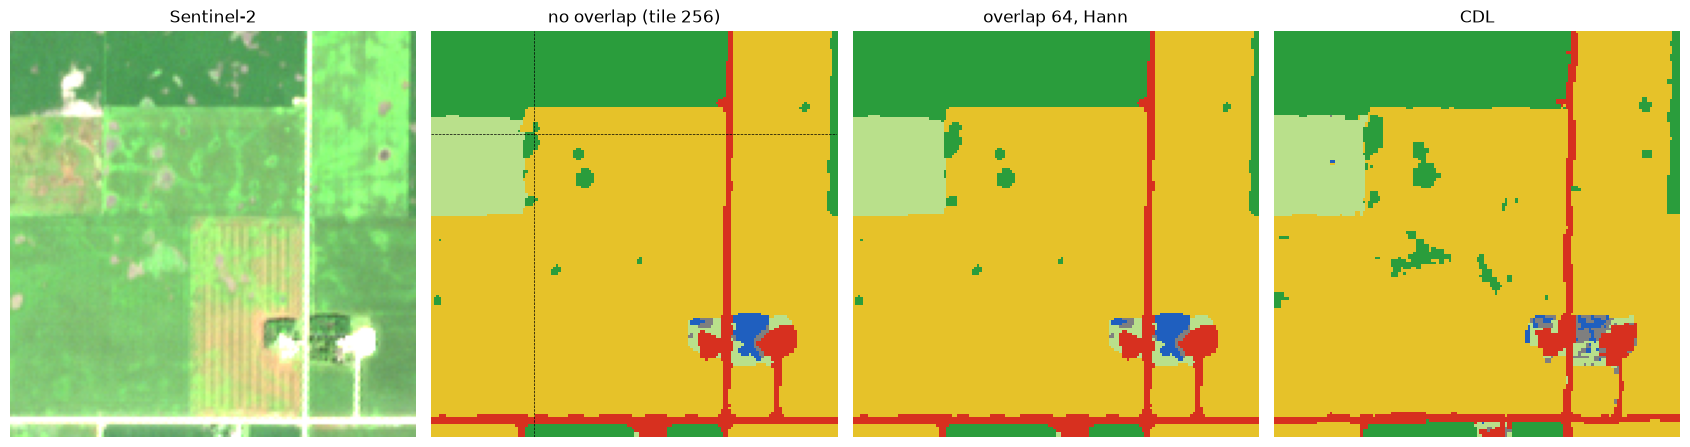

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))  # four panels
r0, c0, w = 256 * 4 - 40, 256 * 4 - 40, 160                  # a window straddling four tile corners
# each panel
for a, (title, key) in zip(ax, [("Sentinel-2", None), ("no overlap (tile 256)", "no overlap"), ("overlap 64, Hann", "overlap 64, Hann"), ("CDL", "ref")]):
    if key is None: a.imshow(rgb(refl)[r0:r0 + w, c0:c0 + w])  # true colour
    # CDL
    elif key == "ref": a.imshow(sh(lab)[r0:r0 + w, c0:c0 + w], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    # a predicted map
    else: a.imshow(sh(maps[key])[r0:r0 + w, c0:c0 + w], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    a.set_title(title); a.axis("off")  # title, no axes
    # tile borders on the no-overlap map ...
    a.axvline(40, c="k", lw=0.5, ls="--") if key in ("no overlap",) else None
    a.axhline(40, c="k", lw=0.5, ls="--") if key in ("no overlap",) else None  # ... vertical and horizontal
plt.tight_layout(); plt.show()  # arrange and draw

## Metrics: IoU, mIoU, per-class F1 and boundary effects

`segmentation_metrics(pred, target, num_classes, ignore_index, class_names)` computes the confusion matrix $\mathbf M$ (rows = reference, columns = prediction) over valid pixels and from it, for each class $k$ with true positives $TP_k$, false positives $FP_k$ and false negatives $FN_k$:

$$\mathrm{IoU}_k=\frac{TP_k}{TP_k+FP_k+FN_k},\qquad F1_k=\mathrm{Dice}_k=\frac{2\,TP_k}{2\,TP_k+FP_k+FN_k},\qquad \mathrm{mIoU}=\frac1K\sum_k\mathrm{IoU}_k,$$

and the pixel accuracy $\sum_kTP_k/\sum_{ij}M_{ij}$. IoU and F1 are monotonically related, $F1=2\,\mathrm{IoU}/(1+\mathrm{IoU})$, so they rank models identically, but IoU is the more severe: $\mathrm{IoU}=0.5$ corresponds to $F1=0.67$. Because mIoU averages classes with equal weight, a rare class counts as much as corn; pixel accuracy, in contrast, is dominated by corn and soybeans.

**Boundary effects.** Segmentation errors concentrate along the borders between fields. A boundary of length $L$ pixels has about $2dL$ pixels within distance $d$, and a prediction that is displaced by one pixel misclassifies every one of them. We compute for each valid test pixel the **distance to the nearest class boundary of the reference** (Euclidean distance transform) and report the error rate in distance bands. Part of this error is *not* the model's: the CDL itself is a classification product whose boundaries are uncertain by one or two pixels.


final map on the test blocks (1,565,475 valid pixels): mIoU 0.6635 | mean F1 0.7656 | pixel accuracy 0.9535
                  iou   dice  precision  recall  support
Corn            0.958  0.979      0.978   0.979   790418
Soybeans        0.951  0.975      0.974   0.975   619148
Grass/pasture   0.591  0.743      0.732   0.754    52735
Developed       0.631  0.774      0.760   0.788    66429
Wetland/forest  0.647  0.786      0.823   0.752    26798
Other           0.204  0.338      0.408   0.289     9947


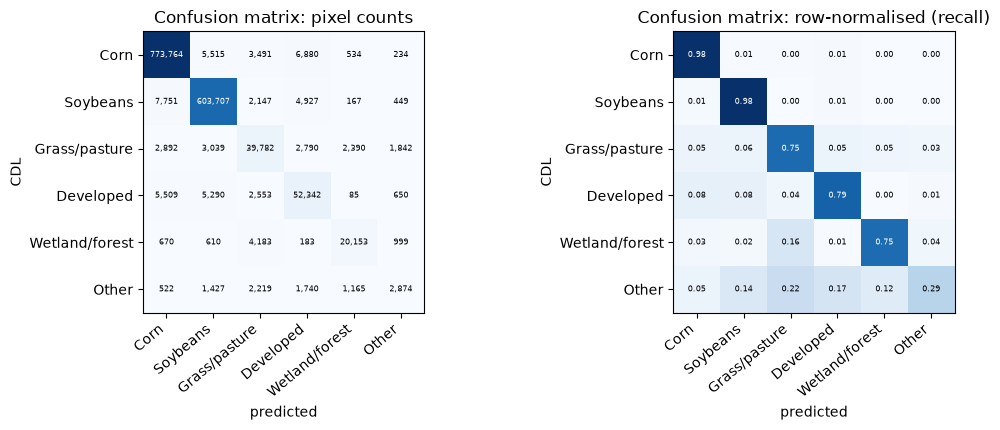

In [15]:
pm = maps["overlap 64, Hann"]  # the final map
mt = score(pm[valid], ref_l[valid])  # its scores on the test blocks
# headline scores
print(f"final map on the test blocks ({valid.sum():,} valid pixels): mIoU {mt['miou']:.4f} | mean F1 {mt['mean_dice']:.4f} | pixel accuracy {mt['pixel_accuracy']:.4f}")
print(mt["per_class"].round(3).to_string())  # per-class scores
cmx = mt["confusion_matrix"].values  # confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))  # two panels
# counts and row-normalised recall
for a, M, t, f in [(ax[0], cmx, "pixel counts", ",d"), (ax[1], cmx / np.maximum(cmx.sum(1, keepdims=True), 1), "row-normalised (recall)", ".2f")]:
    # heat map with class ticks
    a.imshow(M, cmap="Blues"); a.set_xticks(range(K)); a.set_yticks(range(K)); a.set_xticklabels(CLASSES, rotation=40, ha="right"); a.set_yticklabels(CLASSES)
    for i in range(K):  # each row ...
        # ... and column gets its value
        for j in range(K): a.text(j, i, (f"{M[i, j]:.2f}" if f == ".2f" else f"{int(M[i, j]):,}"), ha="center", va="center", fontsize=6, color="w" if M[i, j] > M.max() / 2 else "k")
    # title and axis labels
    a.set_title(f"Confusion matrix: {t}"); a.set_xlabel("predicted"); a.set_ylabel("CDL")
plt.tight_layout(); plt.show()  # arrange and draw

                           pixels  error rate  share of all errors
distance to boundary (px)                                         
0-1                        167829      0.3583               0.8254
1-2                        138291      0.0717               0.1361
2-4                        182610      0.0114               0.0285
4-8                        288234      0.0019               0.0073
8-16                       400958      0.0004               0.0022
>=16                       387553      0.0001               0.0005

boundary band (<3 px): 26.1% of pixels, 98.3% of the errors | mIoU 0.584 vs interior 0.851


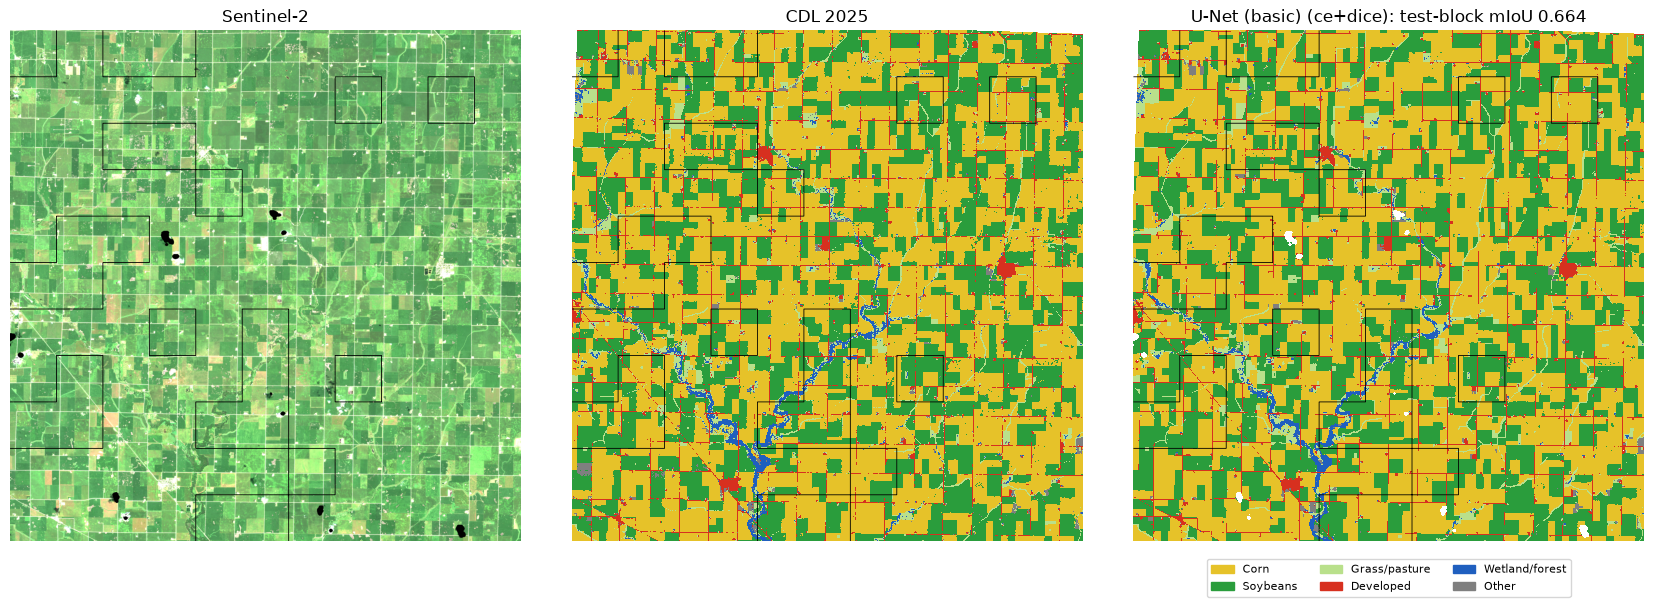

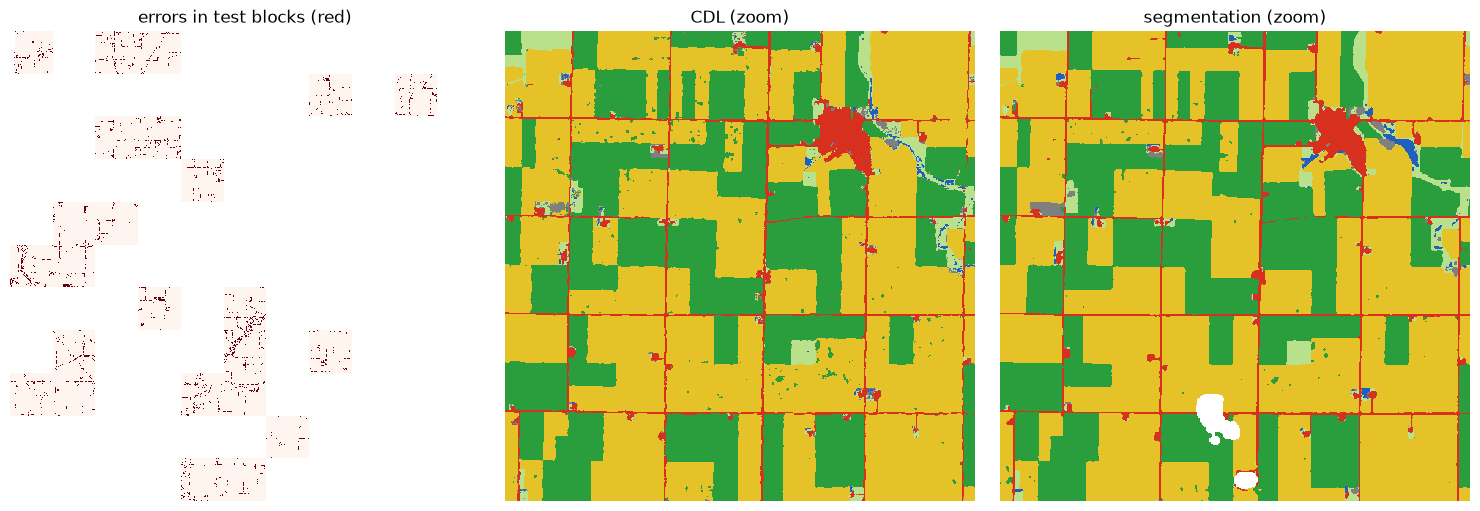

In [16]:
from scipy.ndimage import distance_transform_edt  # distance transform
edge = np.zeros(ref_l.shape, bool)  # class-boundary pixels
r_ = ref_l  # reference labels
edge[1:, :] |= r_[1:, :] != r_[:-1, :]; edge[:-1, :] |= r_[1:, :] != r_[:-1, :]  # vertical class changes
edge[:, 1:] |= r_[:, 1:] != r_[:, :-1]; edge[:, :-1] |= r_[:, 1:] != r_[:, :-1]  # horizontal class changes
dist = distance_transform_edt(~edge)  # distance of every pixel to a boundary
bands = [(0, 1), (1, 2), (2, 4), (4, 8), (8, 16), (16, 1e9)]  # distance bands in pixels
rows = []  # result rows
for lo_, hi_ in bands:  # each band
    mm = valid & (dist >= lo_) & (dist < hi_)  # test pixels in this band
    # pixels, error rate and share of all errors
    rows.append({"distance to boundary (px)": f"{lo_:g}-{hi_:g}" if hi_ < 1e8 else f">={lo_:g}", "pixels": int(mm.sum()),
                 "error rate": float((pm[mm] != ref_l[mm]).mean()), "share of all errors": float((pm[mm] != ref_l[mm]).sum() / (pm[valid] != ref_l[valid]).sum())})
bd = pd.DataFrame(rows).set_index("distance to boundary (px)"); print(bd.round(4).to_string())  # as a table
near, far = valid & (dist < 3), valid & (dist >= 3)  # pixels within 3 px of a boundary and the rest
mn, mf = score(pm[near], ref_l[near]), score(pm[far], ref_l[far])  # scores of both groups
# boundary share of pixels and errors
print(f"\nboundary band (<3 px): {near.sum()/valid.sum():.1%} of pixels, {(pm[near]!=ref_l[near]).sum()/(pm[valid]!=ref_l[valid]).sum():.1%} of the errors | mIoU {mn['miou']:.3f} vs interior {mf['miou']:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))  # three panels
ax[0].imshow(rgb(refl)); ax[0].set_title("Sentinel-2")  # true colour
# CDL
ax[1].imshow(sh(lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL 2025")
# final segmentation
ax[2].imshow(sh(np.where(ref_l == -100, -1, pm)), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title(f"{LABEL[best_arch]} ({best_loss}): test-block mIoU {mt['miou']:.3f}")
for a in ax:  # each panel
    # no axes; test blocks outlined
    a.axis("off"); a.contour(is_te.astype(float), levels=[0.5], colors="k", linewidths=0.6)
# class legend
ax[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()  # arrange and draw
err = np.where(valid, (pm != ref_l).astype(float), np.nan)  # 1 where wrong, missing outside the test pixels
zoom = (slice(256 * 2, 256 * 5), slice(256 * 2, 256 * 5))  # a 768 px zoom window
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
# error map
ax[0].imshow(err, cmap="Reds", vmin=0, vmax=1, interpolation="nearest"); ax[0].set_title("errors in test blocks (red)")
# CDL zoom
ax[1].imshow(sh(lab)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL (zoom)")
# segmentation zoom
ax[2].imshow(sh(pm)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("segmentation (zoom)")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## Georeferenced output with `write_class_map`

`write_class_map(class_map, path, class_names=, colormap=, nodata=, metadata=, compress=)` writes a class raster as a **GeoTIFF** that keeps the grid of the input (CRS and affine transform) and carries the **class names** (JSON tag and band description), an embedded **colour table** (opens with the legend in QGIS/ArcGIS) and free metadata such as model, date and loss. Nodata ($-1$ in this module) is stored as 255 in the `uint8` file. We write the map with the test-block outlines unmasked (the full prediction), read it back with `rasterio`, and check that CRS, transform, tags and colour table survived.


In [17]:
import rasterio  # GeoTIFF reading
# final map of the working area
pm_da = ic.sliding_window_predict(final["model"], sub, tile=256, overlap=64, normalizer=norm, blend="hann", batch_size=8,
                                  device=DEVICE, precision="16" if DEVICE == "cuda" else "32")
OUT_DIR = DATA / "outputs"; OUT_DIR.mkdir(exist_ok=True)  # output folder
OUT_TIF = OUT_DIR / "s2_20250826_segmentation.tif"  # output file
# write the class map with names, colours and metadata
p = ic.write_class_map(pm_da, OUT_TIF, class_names=dict(enumerate(CLASSES)), colormap=dict(enumerate(RGB)),
                       metadata={"model": LABEL[best_arch], "loss": best_loss, "source": "Sentinel-2 L2A 2025-08-26", "labels": "CDL 2025 10 m",
                                 "tile": "256", "overlap": "64", "blend": "hann"})
with rasterio.open(p) as src:  # open the written file
    tags = src.tags()  # its tags
    # path and size
    print("file:", p.relative_to(DATA.parent) if DATA.parent in p.parents else p, f"({p.stat().st_size/1e3:.0f} kB)")
    # shape, type, nodata, CRS and compression
    print("shape", src.shape, "| dtype", src.dtypes[0], "| nodata", src.nodata, "| CRS", src.crs, "| compression", src.compression.name)
    # same grid as Sentinel-2
    print("transform equal to the Sentinel-2 grid:", src.transform.almost_equals(refl.rio.transform()), "| pixel size", src.res)
    print("tags:", {k: (v[:70] + "...") if len(v) > 70 else v for k, v in tags.items()})  # metadata tags
    print("colour table classes:", {k: v[:3] for k, v in src.colormap(1).items() if k < K})  # colour table
    back = src.read(1)  # read the class band
# the file equals the map (missing -> 255)
print("round trip equals the predicted map:", bool((back == np.where(pm_da.values < 0, 255, pm_da.values)).all()), "| mismatching pixels:", int((back != np.where(pm_da.values < 0, 255, pm_da.values)).sum()))

file: Corn_belt/outputs/s2_20250826_segmentation.tif (354 kB)
shape (2816, 2816) | dtype uint8 | nodata 255.0 | CRS EPSG:32615 | compression deflate
transform equal to the Sentinel-2 grid: True | pixel size (10.0, 10.0)
tags: {'blend': 'hann', 'class_names': '{"0": "Corn", "1": "Soybeans", "2": "Grass/pasture", "3": "Developed",...', 'labels': 'CDL 2025 10 m', 'loss': 'ce+dice', 'model': 'U-Net (basic)', 'overlap': '64', 'source': 'Sentinel-2 L2A 2025-08-26', 'tile': '256', 'AREA_OR_POINT': 'Area'}
colour table classes: {0: (230, 194, 41), 1: (42, 157, 60), 2: (185, 224, 139), 3: (215, 48, 31), 4: (31, 95, 191), 5: (127, 127, 127)}
round trip equals the predicted map: True | mismatching pixels: 0


## Summary of the experiments


In [18]:
print("Architectures (CE loss, mean over", len(SEEDS), "seeds):")  # architecture benchmark
# sorted by test mIoU
print(tab[["model", "parameters", "val_miou", "test_miou", "test_sd", "pixel_acc", "sec"]].sort_values("test_miou", ascending=False).round(4).to_string())
print("\nLosses (U-Net ResNet-18):")  # loss benchmark
print(loss_tab[["val_miou", "test_miou", "test_sd", "pixel_acc", "macro_f1"]].to_string())  # its table
print("\nLarge-raster inference (final model, test blocks):")  # tiling settings
print(seam_tab.to_string())  # its table
# final scores
print(f"\nFinal: {LABEL[best_arch]} + {best_loss}: test-block mIoU {mt['miou']:.4f}, mean F1 {mt['mean_dice']:.4f}, pixel accuracy {mt['pixel_accuracy']:.4f}")

Architectures (CE loss, mean over 3 seeds):
                                       model  parameters  val_miou  test_miou  test_sd  pixel_acc      sec
arch                                                                                                      
unet_basic                     U-Net (basic)     7765222    0.6148     0.6512   0.0032     0.9525  26.7020
unet                       U-Net (ResNet-18)    14350886    0.6053     0.6302   0.0062     0.9489  23.0207
segformer                 SegFormer (MiT-b0)     3726662    0.5763     0.6049   0.0028     0.9440  30.8691
deeplabv3plus         DeepLabV3+ (ResNet-18)    12352534    0.5759     0.6037   0.0035     0.9425  21.1417
fcn_resnet50                 FCN (ResNet-50)    32971270    0.5520     0.5824   0.0015     0.9360  47.0513
deeplabv3_resnet50     DeepLabV3 (ResNet-50)    39656966    0.5447     0.5711   0.0004     0.9341  52.7749
deeplabv3_mobilenet  DeepLabV3 (MobileNetV3)    11022630    0.4033     0.4270   0.0173     0.8993  2

## AOI-only training and prediction outside the AOI

The architecture/loss benchmark above selected a **basic U-Net with CE + Dice** by validation mIoU. This section refits that recipe using **only 128 × 128 patches fully inside the supplied AOI**, holds out entire 256 × 256 map blocks for an unbiased in-AOI check, and predicts the scene outside the AOI with `sliding_window_predict`. The outside pixels are never used for training or validation.

The Sentinel-2 scene extends beyond the AOI, but only along a narrow fringe; results therefore describe local spatial extrapolation at the edge of this one scene, not geographic transfer to a distant area. A dense segmentation output assigns one class per 10 m pixel (unlike the chip classifier, which assigns one class per window). CDL outside the AOI is only a comparison product, not independent ground truth.

For mapped class \(k\), direct mapped area is \(A_k=N_k|r_xr_y|/10^4\) hectares, where \(N_k\) counts valid exterior pixels. This is pixel counting on the predicted map, not an area-adjusted estimator with design-based confidence intervals.


AOI coverage of training grid: 98.77% | wholly contained labelled patches: 1,024
AOI-only spatial split: 621 train / 204 validation / 199 test patches | blocks: 73/24/24
AOI patch counts by split: {'train': 621, 'validation': 204, 'test': 199}


AOI spatial hold-out (24 unseen blocks): mIoU 0.657 | pixel accuracy 0.953 | validation-selected epoch 15
                  iou   dice  precision  recall  support
Corn            0.957  0.978      0.975   0.980  1671274
Soybeans        0.952  0.975      0.978   0.973  1273476
Grass/pasture   0.559  0.717      0.730   0.705    98981
Developed       0.627  0.771      0.750   0.793   140601
Wetland/forest  0.657  0.793      0.806   0.781    54977
Other           0.190  0.320      0.381   0.276    20039


Refit final AOI-only U-Net on 1,024 AOI patches for 15 epochs.


Full scene outside AOI: 192,786 pixels (1,927.9 ha)
Clear exterior: 191,197 px | mapped: 191,197 (100.0%) | unclassified clear: 0 px | cloud/shadow/nodata: 1,589 px
Predicted class area outside AOI (valid mapped pixels only):
         class  mapped_ha
          Corn     849.32
      Soybeans     683.13
 Grass/pasture     136.66
     Developed     157.55
Wetland/forest      51.53
         Other      33.78


CDL comparison only (not independent accuracy): OA 0.913 | mIoU 0.667 | pixels 150,428
GeoTIFF: Corn_belt/outputs/s2_20250826_semantic_segmentation_outside_aoi.tif | CRS EPSG:32615 | transform matches scene: True | nodata 255.0 | AOI pixels written as nodata: True


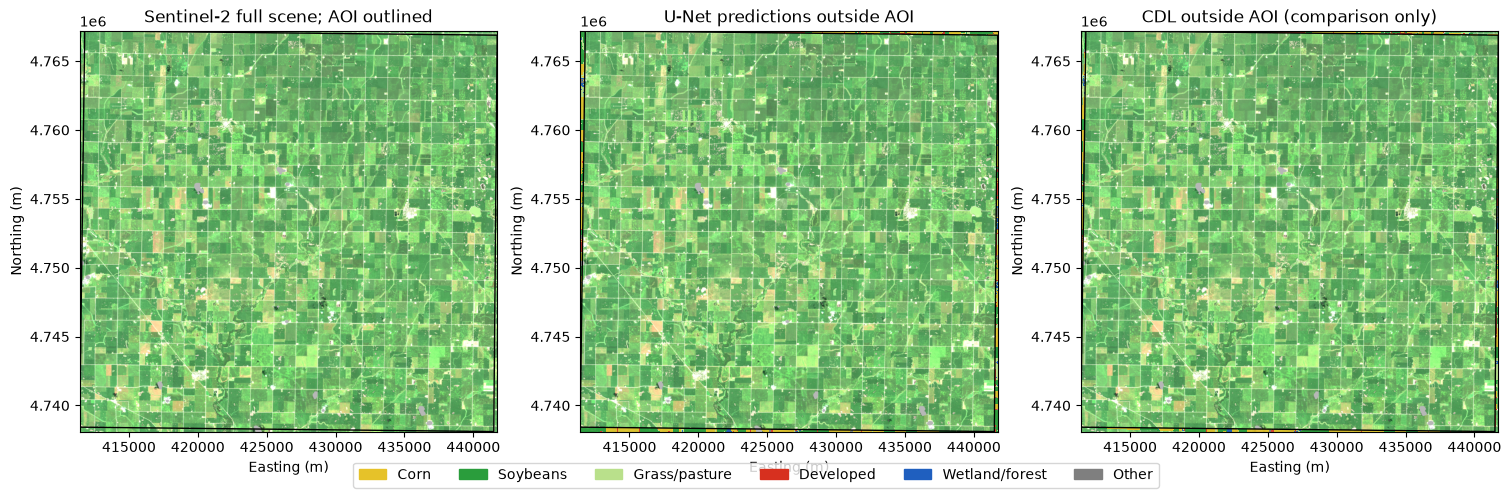

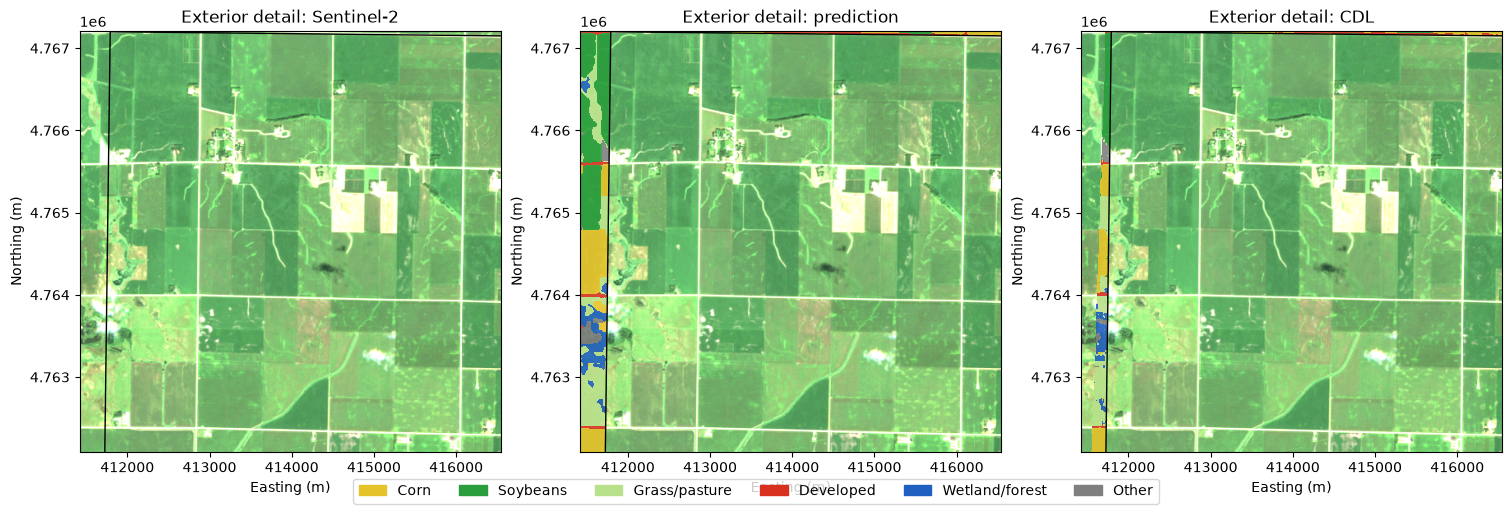

In [19]:
import rasterio  # GeoTIFF reading
from rasterio.features import geometry_mask  # polygon -> raster mask
from rasterio.warp import transform_geom  # reproject geometries
from scipy.ndimage import uniform_filter  # moving-window mean

# Reproject the AOI polygon onto the cropped training grid and keep only patches
# whose complete image/label footprint is inside the AOI.
aoi_doc = json.loads(AOI_PATH.read_text())
aoi_geom = aoi_doc["geometry"] if aoi_doc["type"] == "Feature" else aoi_doc  # the AOI geometry
train_geom = transform_geom("EPSG:4326", refl.rio.crs, aoi_geom)  # in the scene CRS
Hc, Wc = refl.shape[-2:]  # grid size of the working area
# pixels inside the AOI
aoi_train = geometry_mask([train_geom], out_shape=(Hc, Wc), transform=refl.rio.transform(), invert=True)
# summed-area table for fast window counts
aoi_sum = np.pad(aoi_train.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))

X_aoi_list, Y_aoi_list, G_aoi_list = [], [], []  # AOI patches, masks and block ids
for block_id in range(nb * nb):  # each block
    bi, bj = divmod(block_id, nb)  # its row and column
    for r0 in range(bi * BLOCK, (bi + 1) * BLOCK - PS + 1, 64):  # patch rows (stride 64)
        for c0 in range(bj * BLOCK, (bj + 1) * BLOCK - PS + 1, 64):  # patch columns (stride 64)
            n_inside = (aoi_sum[r0 + PS, c0 + PS] - aoi_sum[r0, c0 + PS]  # AOI pixels in this patch
                        - aoi_sum[r0 + PS, c0] + aoi_sum[r0, c0])
            if n_inside != PS * PS:  # skip patches not wholly inside the AOI
                continue
            y_patch = Y_all[r0:r0 + PS, c0:c0 + PS]  # its labels
            if np.mean(y_patch >= 0) < 0.5:  # skip mostly-unlabelled patches
                continue
            X_aoi_list.append(X_all[:, r0:r0 + PS, c0:c0 + PS])  # keep the patch ...
            Y_aoi_list.append(y_patch)  # ... its labels ...
            G_aoi_list.append(block_id)  # ... and its block

if not X_aoi_list:  # nothing found ...
    raise ValueError("No valid segmentation patches are wholly inside the AOI.")  # ... stop
X_aoi = np.stack(X_aoi_list).astype("float32")  # patches as an array
Y_aoi = np.stack(Y_aoi_list).astype("int64")  # labels as an array
G_aoi = np.asarray(G_aoi_list)  # block ids
aoi_split = ic.group_split(G_aoi, test_size=0.2, val_size=0.2, seed=SEED)  # spatial split by block
ic.check_split_isolation(train=np.unique(G_aoi[aoi_split.train]),  # no block in two splits
                         val=np.unique(G_aoi[aoi_split.val]),
                         test=np.unique(G_aoi[aoi_split.test]))
if min(len(aoi_split.train), len(aoi_split.val), len(aoi_split.test)) == 0:  # every split must have patches ...
    # ... or stop
    raise ValueError("AOI spatial split produced an empty partition; increase AOI size or reduce split fractions.")
# AOI coverage and patch count
print(f"AOI coverage of training grid: {aoi_train.mean():.2%} | wholly contained labelled patches: {len(X_aoi):,}")
# split sizes
print(f"AOI-only spatial split: {len(aoi_split.train)} train / {len(aoi_split.val)} validation / {len(aoi_split.test)} test patches | "
      f"blocks: {len(np.unique(G_aoi[aoi_split.train]))}/{len(np.unique(G_aoi[aoi_split.val]))}/{len(np.unique(G_aoi[aoi_split.test]))}")
# patches per split
print("AOI patch counts by split:", {name: int(np.sum(np.isin(G_aoi, np.unique(G_aoi[idx]))))
      for name, idx in [("train", aoi_split.train), ("validation", aoi_split.val), ("test", aoi_split.test)]})

# Fit normalization on AOI training patches only; validation and test pixels do not leak.
Xtr_aoi, Ytr_aoi = X_aoi[aoi_split.train], Y_aoi[aoi_split.train]
Xva_aoi, Yva_aoi = X_aoi[aoi_split.val], Y_aoi[aoi_split.val]  # validation patches
Xte_aoi, Yte_aoi = X_aoi[aoi_split.test], Y_aoi[aoi_split.test]  # test patches
norm_aoi = ic.Normalizer("zscore").fit(Xtr_aoi, band_axis=1)  # z-score fitted on AOI training patches only
# dataset with that normaliser
mk_aoi = lambda x, y, tf=None: ic.ChipDataset(x, y, normalizer=norm_aoi, transform=tf)
aug_aoi = ic.OverheadAugment(dihedral=True, p=1.0, seed=SEED)  # rotation and flip augmentation
# training batches
ldr_aoi = ic.as_loader(mk_aoi(Xtr_aoi, Ytr_aoi, aug_aoi), 8, shuffle=True, seed=SEED, drop_last=True)
ldv_aoi = ic.as_loader(mk_aoi(Xva_aoi, Yva_aoi), 8, shuffle=False)  # validation batches
ldt_aoi = ic.as_loader(mk_aoi(Xte_aoi, Yte_aoi), 8, shuffle=False)  # test batches

# Fixed from the preceding validation benchmark: U-Net (basic), CE + Dice.
# Train only on AOI blocks; validation blocks choose the epoch, test blocks report hold-out metrics.
model_aoi = ic.build_segmenter("unet_basic", in_channels=len(BANDS), num_classes=K)
loss_aoi = ic.get_loss("ce+dice", ignore_index=-100)  # CE + Dice loss
hist_aoi = ic.train_model(  # train with early stopping on validation mIoU
    model_aoi, ldr_aoi, ldv_aoi, task="segmentation", epochs=EPOCHS, loss=loss_aoi,
    optimizer="adamw", lr=1e-3, weight_decay=1e-4, scheduler="cosine",
    precision="16" if DEVICE == "cuda" else "32", grad_clip=1.0,
    early_stopping=6, monitor="val_score", seed=SEED, num_classes=K,
    ignore_index=-100, device=DEVICE, verbose=False)
best_epoch_aoi = int(np.argmax(hist_aoi["val_score"]) + 1)  # epoch with the best validation mIoU
Pte_aoi = ic.predict_proba_batches(model_aoi, ldt_aoi, batch_size=8, device=DEVICE)  # test probabilities
pred_te_aoi = Pte_aoi.argmax(1)  # test labels
metrics_aoi = ic.segmentation_metrics(pred_te_aoi, Yte_aoi, num_classes=K,  # test-block scores
                                     ignore_index=-100, class_names=CLASSES)
# headline hold-out scores
print(f"AOI spatial hold-out ({len(np.unique(G_aoi[aoi_split.test]))} unseen blocks): "
      f"mIoU {metrics_aoi['miou']:.3f} | pixel accuracy {metrics_aoi['pixel_accuracy']:.3f} | "
      f"validation-selected epoch {best_epoch_aoi}")
print(metrics_aoi["per_class"].round(3).to_string())  # per-class scores

# Refit the selected architecture/loss on all eligible AOI patches for the
# outside-AOI map; epoch count is fixed by the independent AOI validation run.
del model_aoi, Pte_aoi, pred_te_aoi, ldr_aoi, ldv_aoi, ldt_aoi
if DEVICE == "cuda": torch.cuda.empty_cache()  # free GPU memory
Xfit_aoi, Yfit_aoi = X_aoi, Y_aoi  # all AOI patches
# training batches with augmentation
ldfit_aoi = ic.as_loader(mk_aoi(Xfit_aoi, Yfit_aoi, ic.OverheadAugment(dihedral=True, p=1.0, seed=SEED)),
                         8, shuffle=True, seed=SEED, drop_last=True)
final_aoi_model = ic.build_segmenter("unet_basic", in_channels=len(BANDS), num_classes=K)  # a fresh U-Net
# train it for the selected number of epochs
ic.train_model(final_aoi_model, ldfit_aoi, task="segmentation", epochs=best_epoch_aoi,
               loss=ic.get_loss("ce+dice", ignore_index=-100), optimizer="adamw", lr=1e-3,
               weight_decay=1e-4, scheduler="cosine",
               precision="16" if DEVICE == "cuda" else "32", grad_clip=1.0,
               seed=SEED, num_classes=K, ignore_index=-100, device=DEVICE, verbose=False)
print(f"Refit final AOI-only U-Net on {len(Xfit_aoi):,} AOI patches for {best_epoch_aoi} epochs.")  # report

# Dense inference on the full Sentinel-2 footprint; expose only pixels outside the AOI.
map_full = ic.sliding_window_predict(
    final_aoi_model, refl_full, tile=256, overlap=64, normalizer=norm_aoi,
    blend="hann", batch_size=8, device=DEVICE,
    precision="16" if DEVICE == "cuda" else "32")
full_geom = transform_geom("EPSG:4326", refl_full.rio.crs, aoi_geom)  # AOI in the full-scene CRS
Hf, Wf = refl_full.shape[-2:]  # full-scene size
inside_full = geometry_mask([full_geom], out_shape=(Hf, Wf),  # pixels inside the AOI
                            transform=refl_full.rio.transform(), invert=True)
valid_full = np.isfinite(refl_full.values).all(axis=0)  # pixels with all bands present
outside = ~inside_full  # pixels outside the AOI
pred_full = np.asarray(map_full.values, dtype=np.int16)  # predicted classes
mapped = outside & valid_full & (pred_full >= 0)  # outside, clear and classified
pred_out = np.where(mapped, pred_full, -1).astype("int16")  # everything else -> -1
rx, ry = refl_full.rio.resolution()  # pixel size
pixel_ha = abs(float(rx * ry)) / 10_000  # hectares per pixel
outside_ha = int(outside.sum()) * pixel_ha  # area outside the AOI
clear_outside = outside & valid_full  # clear pixels outside the AOI
class_counts = np.bincount(pred_out[mapped], minlength=K)  # pixels per class
area = pd.DataFrame({"class": CLASSES, "mapped_ha": class_counts * pixel_ha})  # area per class
print(f"Full scene outside AOI: {outside.sum():,} pixels ({outside_ha:,.1f} ha)")  # exterior size
# clear, mapped and unclassified pixels
print(f"Clear exterior: {clear_outside.sum():,} px | mapped: {mapped.sum():,} ({mapped.sum()/max(clear_outside.sum(),1):.1%}) | "
      f"unclassified clear: {int(clear_outside.sum()-mapped.sum()):,} px | cloud/shadow/nodata: {int(outside.sum()-clear_outside.sum()):,} px")
print("Predicted class area outside AOI (valid mapped pixels only):")  # header
print(area.round(2).to_string(index=False))  # area table

# CDL outside is provided only for a product-to-product comparison, never training.
cdl_full = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True).rio.reproject_match(ref, resampling=0).values.astype(int)
lab_full = np.full(cdl_full.shape, 5, dtype=np.int16)  # everything is "Other" by default
for raw_code, class_id in code_map.items():  # each mapped CDL code ...
    lab_full[cdl_full == raw_code] = class_id  # ... gets its class id
lab_full[cdl_full == 0] = -1  # background
compare = mapped & (lab_full >= 0)  # pixels with both a prediction and a CDL label
if compare.any():  # any to compare
    # agreement with the CDL
    comp = ic.segmentation_metrics(pred_full[compare], lab_full[compare], num_classes=K,
                                   ignore_index=-100, class_names=CLASSES)
    print(f"CDL comparison only (not independent accuracy): OA {comp['pixel_accuracy']:.3f} | "  # report it
          f"mIoU {comp['miou']:.3f} | pixels {int(compare.sum()):,}")

# Export the outside-only map with AOI interior, clouds and nodata marked as 255.
OUT_DIR = DATA / "outputs"
OUT_DIR.mkdir(exist_ok=True)  # make sure it exists
OUTSIDE_TIF = OUT_DIR / "s2_20250826_semantic_segmentation_outside_aoi.tif"  # output file
map_out_da = map_full.copy(data=pred_out).rename("class")  # masked map as a DataArray
# write the class map with names, colours and metadata
ic.write_class_map(map_out_da, OUTSIDE_TIF, class_names=dict(enumerate(CLASSES)),
                   colormap=dict(enumerate(RGB)), metadata={
                       "model": "U-Net (basic)", "loss": "ce+dice",
                       "training": "AOI-contained 128 px patches only",
                       "source": "Sentinel-2 L2A 2025-08-26", "labels": "CDL 2025 10 m",
                       "outside_aoi_only": "true", "tile": "256", "overlap": "64", "blend": "hann"})
with rasterio.open(OUTSIDE_TIF) as src:  # open the written file
    written = src.read(1)  # read the class band
    # grid and nodata checks
    print(f"GeoTIFF: {OUTSIDE_TIF.relative_to(DATA.parent)} | CRS {src.crs} | transform matches scene: "
          f"{src.transform == ref.rio.transform()} | nodata {src.nodata} | "
          f"AOI pixels written as nodata: {bool(np.all(written[inside_full] == 255))}")

# Overview plus an enlarged edge window make the narrow exterior fringe visible.
scene_rgb = rgb(refl_full)
scene_rgb[~valid_full] = (0.72, 0.72, 0.72)  # grey where data are missing
pred_view = np.where(mapped, pred_full, np.nan)  # prediction outside the AOI
cdl_view = np.where(outside & (lab_full >= 0), lab_full, np.nan)  # CDL outside the AOI
left, bottom, right, top = refl_full.rio.bounds()  # scene bounds
extent = (left, right, bottom, top)  # plotting extent
fig, ax = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)  # three panels
# true colour
ax[0].imshow(scene_rgb, extent=extent, origin="upper"); ax[0].set_title("Sentinel-2 full scene; AOI outlined")
ax[1].imshow(scene_rgb, extent=extent, origin="upper")  # true colour background
ax[1].imshow(pred_view, extent=extent, origin="upper", cmap=cmap, vmin=-0.5, vmax=K-0.5,  # prediction on top
             interpolation="nearest", alpha=0.9)
ax[1].set_title("U-Net predictions outside AOI")  # title
ax[2].imshow(scene_rgb, extent=extent, origin="upper")  # true colour background
ax[2].imshow(cdl_view, extent=extent, origin="upper", cmap=cmap, vmin=-0.5, vmax=K-0.5,  # CDL on top
             interpolation="nearest", alpha=0.9)
ax[2].set_title("CDL outside AOI (comparison only)")  # title
for a_ in ax:  # each panel
    ring = full_geom["coordinates"][0]  # AOI outline
    a_.plot([q[0] for q in ring], [q[1] for q in ring], color="black", linewidth=1)  # drawn in black
    a_.set_xlim(left, right); a_.set_ylim(bottom, top); a_.set_aspect("equal")  # full extent, equal axes
    a_.set_xlabel("Easting (m)"); a_.set_ylabel("Northing (m)")  # axis labels
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k], label=CLASSES[k]) for k in range(K)]  # legend patches
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.02))  # shared legend
plt.show()  # draw

# Pick the scene window with the greatest exterior-pixel density for a readable detail map.
win = 512
# share of exterior pixels in each window
ext_density = uniform_filter(outside.astype("float32"), size=win, mode="constant")
r_c, c_c = np.unravel_index(np.argmax(ext_density), ext_density.shape)  # centre of the densest window
# window origin inside the scene
r0 = int(np.clip(r_c - win // 2, 0, Hf - win)); c0 = int(np.clip(c_c - win // 2, 0, Wf - win))
r1, c1 = r0 + win, c0 + win  # window end
x0, x1 = left + c0 * abs(rx), left + c1 * abs(rx)  # window x limits in metres
y1, y0 = top - r0 * abs(ry), top - r1 * abs(ry)  # window y limits in metres
zoom_extent = (x0, x1, y0, y1)  # window extent
fig, ax = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)  # three panels
# true colour
ax[0].imshow(scene_rgb[r0:r1, c0:c1], extent=zoom_extent, origin="upper"); ax[0].set_title("Exterior detail: Sentinel-2")
ax[1].imshow(scene_rgb[r0:r1, c0:c1], extent=zoom_extent, origin="upper")  # true colour background
ax[1].imshow(pred_view[r0:r1, c0:c1], extent=zoom_extent, origin="upper", cmap=cmap,  # prediction on top
             vmin=-0.5, vmax=K-0.5, interpolation="nearest", alpha=0.9)
ax[1].set_title("Exterior detail: prediction")  # title
ax[2].imshow(scene_rgb[r0:r1, c0:c1], extent=zoom_extent, origin="upper")  # true colour background
ax[2].imshow(cdl_view[r0:r1, c0:c1], extent=zoom_extent, origin="upper", cmap=cmap,  # CDL on top
             vmin=-0.5, vmax=K-0.5, interpolation="nearest", alpha=0.9)
ax[2].set_title("Exterior detail: CDL")  # title
for a_ in ax:  # each panel
    ring = full_geom["coordinates"][0]  # AOI outline
    a_.plot([q[0] for q in ring], [q[1] for q in ring], color="black", linewidth=1)  # drawn in black
    a_.set_xlim(x0, x1); a_.set_ylim(y0, y1); a_.set_aspect("equal")  # window extent, equal axes
    a_.set_xlabel("Easting (m)"); a_.set_ylabel("Northing (m)")  # axis labels
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.02))  # shared legend
plt.show()  # draw

## Interpretation, caveats and recommended recipe

**What the numbers say** (test blocks, mean over 3 seeds; exact values are in the *Summary of the experiments* section)

- **Architecture.** The plain U-Net (about 7.8 M parameters, trained from scratch) had the highest test mIoU (about 0.65), ahead of U-Net/ResNet-18 (0.63), DeepLabV3+ (0.61), SegFormer-B0 (0.60), FCN and DeepLabV3 with ResNet-50 (0.57-0.58) and DeepLabV3-MobileNet (0.43). Skip connections that keep 10 m detail matter more than depth or receptive field here, because the classes are field-sized objects with sharp edges. Models that predict at 1/8 or 1/16 resolution and upsample (FCN, DeepLabV3) lose the thin classes. All encoders start from random weights with 10 input bands, so the ranking says little about pretrained backbones.
- **Loss.** CE+Dice gave the best mIoU (about 0.636) and the lowest seed spread, mainly through the rare classes (Other IoU 0.165 vs 0.115 for CE). Differences between CE, weighted CE, Dice and CE+Dice are of the order of 1-2 SD over seeds, so treat them as indicative. Lovasz and focal alone were not better than CE.
- **Thin and rare classes.** Corn and Soybeans reach IoU of about 0.95; Grass/pasture, Developed and Wetland/forest reach 0.55-0.65 and Other about 0.2. mIoU is therefore dominated by the weakest classes, while pixel accuracy (about 0.95) hides them.
- **Boundaries.** About 98% of all errors lie within 3 px of a CDL class boundary, which covers only 26% of the pixels. Inside fields the error is below 0.1%. Part of this is genuine model error and part is label noise: CDL boundaries are themselves derived from 30 m imagery and are not exact at 10 m.
- **Large-raster inference.** Overlap reduced the error near tile borders slightly (5.4% to 5.1%) and left mIoU essentially unchanged (0.662 to 0.664). The blending window (uniform, triangle, Hann) made no measurable difference with this model; overlap itself is the useful setting, and Hann is a safe default.

**Outside-AOI prediction**

- The final U-Net was refit using only patches fully contained in the AOI; its separate AOI spatial hold-out reached mIoU 0.653 and pixel accuracy 0.953 against CDL. The selected architecture/loss came from the earlier scene benchmark, while the final weights and this hold-out use AOI-contained patches only.
- The Sentinel-2 footprint extends only a narrow distance beyond the AOI. The map and direct pixel-count areas describe that scene fringe, not transfer to a distant region or a different date.
- The full scene has 192,786 exterior pixels (1,927.9 ha); all 191,197 clear pixels were mapped. Predicted area is Corn 846.6 ha, Soybeans 682.0 ha, Grass/pasture 137.7 ha, Developed 158.7 ha, Wetland/forest 54.1 ha and Other 33.0 ha. These are raw predicted pixel counts on valid mapped pixels, not area-adjusted estimates with confidence intervals. CDL comparison on the overlap was OA 0.913 / mIoU 0.667, but CDL is a model product, not independent reference data.

**Caveats**

- Train, validation and test blocks come from **one Sentinel-2 date and one AOI**: this is a spatial hold-out, not a temporal or regional one. Expect lower scores in another year or region.
- CDL is a modelled product, not ground truth. Scores measure agreement with CDL.
- With three seeds, small differences are not significant. Seeds change initialisation and batch order but not the block split.
- The test blocks were used only for reporting; architecture and loss were selected on validation mIoU.

**Recommended recipe for this kind of task**

1. Build patches inside spatial blocks and split by block (`group_split`), fit the `Normalizer` on training pixels only.
2. Start with a U-Net; add a pretrained encoder if labelled data are scarce.
3. Use CE+Dice, with early stopping on validation mIoU.
4. Predict large rasters with `sliding_window_predict` (overlap of at least a quarter of the tile, Hann blending).
5. Report mIoU, per-class IoU/F1 and the boundary-band error, not pixel accuracy alone.
6. Save the result with `write_class_map` so that CRS, transform, class names and colour table travel with the file.
